# Backtest — Reversión a la media Donchian sobre Binance USDⓈ-M Perpetuals (piloto Coinbase50)

**Réplica del backtest de CME** (`MeanReversion_IBKR_CME_Bitcoin.ipynb`) sobre el nuevo activo:
misma hipótesis, mismas reglas de señal/sizing/barreras, mismo flujo del skill `backtester`
(sesgos declarados → datos reales → motor con costes reales → baseline sin optimizar →
walk-forward con purga/embargo → DSR/PBO → cuantificación de sesgos → checklist → veredicto).
Lo que cambia es el **activo, el módulo de datos y el motor**: en vez de `ib_async` sobre
futuros MBT/BRR del CME, este notebook usa los módulos de este mismo feature branch
construidos específicamente para Binance:

| | CME (`MeanReversion_IBKR_CME_Bitcoin.ipynb`) | Binance (este notebook) |
|---|---|---|
| Datos históricos | `ib_async` + `qsCrypto.ibkr.contracts.front_month` | `qsCrypto.backtest.binance_data.fetch_pilot_universe` (`GET /fapi/v1/klines`, `GET /fapi/v1/fundingRate`, públicos, cacheados) |
| Universo | `MBT`/`BRR` — dos contratos del MISMO subyacente | `qsCrypto.config.universe.load_universe()` — 5 monedas del piloto Coinbase50∩Binance (`universe_coinbase50_binance.yaml`) |
| Motor de backtest | `run_turtle()` inline en el notebook | `qsCrypto.backtest.engine.run_backtest()` — reutiliza literalmente `compute_n`/`is_flat_bar` de `qsCrypto.strategy.strategy`, el módulo que corre en vivo |
| Indicador N / canal | fórmula Turtle inline | la MISMA fórmula, pero importada del módulo de estrategia en vivo (paridad bit-a-bit, no reimplementación) |
| Comisión | USD fijos por contrato | bps de nocional (taker) |
| Slippage | ticks (`minTick` del contrato) | bps sobre el precio |
| Funding | **no existe** (`FUNDING=0`, el carry va en el precio forward) | **existe y se cobra de verdad** — histórico real de `fundingRate`, liquidado cada 8h |
| Tamaño de posición | contratos ENTEROS (`floor`) | cantidad continua (Binance perp no impone lote entero en el rango operado aquí) |
| Sesgo de roll | 🔴 severo — la serie se cose sin ajustar en cada vencimiento | **no aplica** — un perpetuo no vence, no hay roll que medir |
| Estadística de validación | ad-hoc, inline en el notebook | `qsCrypto.backtest.skill_stats.{bias_audit,purged_cv,stats_tests}` — módulos genéricos, sin dependencias de IBKR ni de Binance |

**Esto es una validación INDEPENDIENTE, no una copia del resultado de CME.** Ese backtest en CME
ya reporta fallar varios criterios de viabilidad (ver skill `MR_BTC_System`). El universo, la
microestructura (24/7 sin sesiones ni RTH), el modelo de costes (bps + funding recurrente en vez
de comisión fija en USD/contrato + slippage en ticks) y el ruido de un perpetuo cripto son
genuinamente distintos: no se puede asumir viabilidad por analogía, hay que medirla de nuevo.

**Todos los números de este notebook son la salida real de ejecutarlo.** La versión anterior de
este archivo contenía una celda de texto con cifras de resultado escritas a mano en vez de
producidas por el propio notebook — exactamente el patrón de irreproducibilidad que el skill
`backtester` prohíbe. Aquí cada cifra sale de una celda de código que la calcula in situ.

## Tabla de sesgos declarados (antes de correr nada)

| # | Sesgo | Impacto | Control en este notebook |
|---|-------|---------|---------------------------|
| 1 | **Look-ahead** | 🟢 Controlado | `compute_n` y el canal Donchian se importan LITERALMENTE de `qsCrypto.strategy.strategy` (el módulo que corre en vivo), no se re-derivan. Test de truncamiento (§4) sobre ambas features. |
| 2 | **Survivorship** | 🟡 Moderado | Universo piloto = 5 monedas listadas en Binance perps desde antes de 2022-01-01, todas veteranas en la muestra completa (§2). El sesgo residual está en la CURACIÓN del piloto (elegidas por liquidez/market-cap actual), no en la construcción de la muestra. |
| 3 | **Overfitting** | 🔴 Severo (medido) | Rejilla deliberadamente pequeña (`entry_bars` × `stop_n`, 6 configuraciones); Deflated Sharpe y PBO calculados con `n_trials` = tamaño real de la rejilla (§8). |
| 4 | **Costes ignorados** | 🟢 Controlado | Fees en bps de nocional (taker) + funding REAL histórico (`GET /fapi/v1/fundingRate`), aplicado en cada liquidación de 8h — nunca un coste inventado. Barrido de sensibilidad en §9.3. |
| 5 | **Diversificación ilusoria** | 🔴 Severo (medido) | 5 monedas del piloto están en el MISMO régimen de riesgo cripto; §9.2 mide el número EFECTIVO de apuestas independientes vía autovalores de la correlación, no se asume. |
| 6 | **Roll de contrato** | ⚪ No aplica | Un perpetuo no vence: no hay serie cosida ni salto de roll que medir (a diferencia de MBT/BRR en CME). |

**Lo que importa leer primero, antes que cualquier Sharpe:** si el sistema pierde dinero incluso
en el escenario "Sin costes" del barrido de §9.3, el problema es de EDGE, no de fricción — y
ningún ajuste de comisión o slippage lo puede arreglar.

## 1. Setup y configuración

In [68]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 50)

plt.rcParams.update({
    "figure.figsize": (14, 6), "axes.grid": True, "grid.alpha": 0.25,
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
})

# Raíz del repo: se sube hasta encontrar pyproject.toml, así el notebook funciona
# tanto si el kernel arranca en notebooks/ como en la raíz.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)

# Módulos del proyecto — los mismos que ejecuta `run_pilot_validation.py`,
# desglosados aquí celda a celda para que cada número sea auditable.
from qsCrypto.config.universe import load_universe
from qsCrypto.backtest.binance_data import fetch_pilot_universe
from qsCrypto.backtest.engine import BacktestParams, run_backtest
from qsCrypto.strategy.strategy import compute_n, is_flat_bar
from qsCrypto.backtest.skill_stats.bias_audit import (
    assert_no_lookahead, pnl_concentration, effective_bets,
    cost_sensitivity, mc_bootstrap_trades, equity_metrics,
)
from qsCrypto.backtest.skill_stats.purged_cv import walk_forward_folds
from qsCrypto.backtest.skill_stats.stats_tests import (
    deflated_sharpe_ratio, fold_ttest, pbo_cscv,
)

print(f"ROOT : {ROOT}")
print("Setup OK")

ROOT : /Users/diegoochoa/Projects/Intraday_MR_BTC
Setup OK


### 1.1 Parámetros — canónicos del skill `/turtlerisk`, sin optimizar

`BacktestParams` (`qsCrypto.backtest.engine`) trae los valores canónicos por defecto: los MISMOS
que se validaron en CME (`entry_bars=20`, `atr_period=20`, `stop_n=1.0`, `add_n=0.5`,
`max_units=4`, objetivo en el medio del canal, vertical a 10 barras). No se recalibran para
Binance antes de correr el baseline — igual que en CME, la tesis se contrasta con parámetros
FIJOS y el walk-forward de §7 es un diagnóstico de estabilidad, no el sistema que se propone
operar.

In [69]:
BASELINE = BacktestParams()
print(BASELINE)

FLAGSHIP = "BTCUSDT"     # símbolo de referencia para WFO, DSR/PBO y Monte Carlo
FREQ = 365                # barras/año para Sharpe/Sortino — cripto opera 24/7 (252 sería TradFi)
INTERVAL = "30m"          # misma granularidad que el backtest de CME (30 min)
START = "2020-01-01"      # todas las monedas del piloto ya cotizaban como perpetuo
END = "2026-09-09 17:30:00"  # ancla explícita: la muestra no cambia según el día en que se corra

BacktestParams(entry_bars=20, atr_period=20, stop_n=1.0, add_n=0.5, max_units=4, max_hold_bars=10, tp_mode='mid_channel', take_n=5.0, risk_per_trade=0.01, equity0=10000.0, fee_bps=0.0002, slip_bps=0.0001, max_gross_lev=4.0, use_dd_rule=True, allow_short=True, require_confirmation=True)


### 1.2 Costes — un perpetuo SÍ paga funding, y aquí se cobra de verdad

Es la diferencia de modelado más importante frente al backtest de CME:

| | Futuro CME (MBT/BRR) | Perpetuo Binance |
|---|---|---|
| Comisión | USD fijos por contrato | `fee_bps` × nocional, por lado |
| Slippage | ticks (`minTick`) | `slip_bps` sobre el precio |
| Funding | **no existe** — el carry va en el precio forward | **liquidación real cada 8h**, histórico descargado de `GET /fapi/v1/fundingRate` |

En CME, `FUNDING=0` estaba fijado deliberadamente porque cobrárselo a un futuro habría sido un
coste inventado. Aquí es al revés: el funding es un coste real del instrumento y omitirlo
sería el sesgo — `run_backtest` lo aplica en cada barra de liquidación con la tasa histórica
real, no con un supuesto.

In [70]:
print(f"  fee_bps (taker, un lado)   : {BASELINE.fee_bps*1e4:.2f} bps")
print(f"  slip_bps (un lado)         : {BASELINE.slip_bps*1e4:.2f} bps")
print(f"  coste round-trip aprox.    : {(BASELINE.fee_bps+BASELINE.slip_bps)*2*1e4:.2f} bps de nocional")
print(f"  funding                   : histórico REAL por símbolo (ver §3), liquidado cada 8h")
print(f"  max_gross_lev              : {BASELINE.max_gross_lev}x")

  fee_bps (taker, un lado)   : 2.00 bps
  slip_bps (un lado)         : 1.00 bps
  coste round-trip aprox.    : 6.00 bps de nocional
  funding                   : histórico REAL por símbolo (ver §3), liquidado cada 8h
  max_gross_lev              : 4.0x


## 2. Universo — piloto Coinbase50 ∩ Binance USDⓈ-M Perpetuals

A diferencia de CME (dos contratos sobre el MISMO subyacente, `MBT`/`BRR`), el piloto de Binance
son **cinco monedas distintas** de `qsCrypto/config/universe_coinbase50_binance.yaml`, cargadas
con el loader del propio módulo (`load_universe`) en vez de hardcodearlas en el notebook. Esto
cambia la naturaleza del sesgo de diversificación: en CME el `n_eff≈1` era una certeza estructural
(mismo subyacente); aquí es una pregunta empírica que se mide en §9.2 — cinco monedas del régimen
cripto podrían diversificar algo, o casi nada.

In [71]:
UNIVERSE = load_universe()   # pilot_only=True por defecto
SYMBOLS = UNIVERSE.symbols
CORR_GROUPS = UNIVERSE.corr_groups_by_group()

print(f"Universo        : {UNIVERSE.universe_name}")
print(f"Símbolos piloto : {SYMBOLS}")
print(f"Grupos de correlación:")
for g, syms in CORR_GROUPS.items():
    print(f"  {g:<16}: {sorted(syms)}")
assert FLAGSHIP in SYMBOLS, "flagship no esta en el universo piloto"

Universo        : coinbase50_pilot_v1
Símbolos piloto : ['BTCUSDT', 'ETHUSDT', 'SOLUSDT', 'AVAXUSDT', 'LINKUSDT']
Grupos de correlación:
  layer1_major    : ['BTCUSDT', 'ETHUSDT']
  layer1_alt      : ['AVAXUSDT', 'SOLUSDT']
  defi            : ['LINKUSDT']


## 3. Descarga de datos — reales, cacheados en disco

`GET /fapi/v1/klines` (30m) y `GET /fapi/v1/fundingRate`, ambos endpoints públicos de Binance
(sin API key), paginados y cacheados en `data_cache/binance/{30m,funding}/` — mismo patrón que
`data_cache/ibkr/{barSize}/` en el notebook de CME. `END` (§1.1) ancla la ventana pedida: como en
CME, la muestra no debe alargarse sola cada vez que se reejecuta el notebook.

In [72]:
DATA, FUNDING = fetch_pilot_universe(SYMBOLS, interval=INTERVAL, start=START, end=END)

INV = pd.DataFrame([
    {"symbol": s, "inicio": DATA[s].index[0], "fin": DATA[s].index[-1],
     "barras": len(DATA[s]),
     "años": round((DATA[s].index[-1] - DATA[s].index[0]).days / 365.25, 2),
     "liquidaciones_funding": len(FUNDING[s]),
     "precio_ini": DATA[s]["close"].iloc[0], "precio_fin": DATA[s]["close"].iloc[-1]}
    for s in SYMBOLS])
display(INV)

assert all(len(DATA[s]) > 200 for s in SYMBOLS), "algún símbolo con muestra insuficiente"
print("\n✓ Datos descargados/cacheados para los", len(SYMBOLS), "símbolos del piloto")

,symbol,inicio,fin,barras,años,liquidaciones_funding,precio_ini,precio_fin
0,BTCUSDT,2022-01-01,2026-09-09 17:30:00,82212,4.69,5139,46378.600,78737.900
1,ETHUSDT,2022-01-01,2026-09-09 17:30:00,82212,4.69,5139,3696.810,2492.540
2,SOLUSDT,2022-01-01,2026-09-09 17:30:00,82212,4.69,5214,171.210,103.490
3,AVAXUSDT,2022-01-01,2026-09-09 17:30:00,82212,4.69,5139,110.668,7.928
4,LINKUSDT,2022-01-01,2026-09-09 17:30:00,82212,4.69,5139,19.651,11.992



✓ Datos descargados/cacheados para los 5 símbolos del piloto


In [73]:
# Velas planas (is_flat_bar): sin recorrido observable ni volumen. En CME el
# umbral de referencia con RTH era ~1%; en un perpetuo 24/7 sin pausas de sesión
# se espera aún menos — si aparece un % alto, es señal de un feed degradado, no
# de mercado cerrado (Binance perps no cierran).
for s in SYMBOLS:
    d = DATA[s]
    flat_pct = np.mean([is_flat_bar(h, l, v) for h, l, v in
                        zip(d["high"], d["low"], d["volume"])])
    print(f"  {s:<10} velas planas: {flat_pct:.2%}")

  BTCUSDT    velas planas: 0.00%
  ETHUSDT    velas planas: 0.00%
  SOLUSDT    velas planas: 0.00%
  AVAXUSDT   velas planas: 0.00%
  LINKUSDT   velas planas: 0.00%


## 4. Indicadores y test de look-ahead

`N` y el canal Donchian se importan de `qsCrypto.strategy.strategy` — el módulo que ejecuta la
estrategia EN VIVO — en vez de reimplementarse en el notebook, como sí ocurre en el backtest de
CME (que define `compute_n` inline porque no existía todavía un módulo de estrategia
compartido). Aquí la paridad backtest↔vivo es estructural, no un test aparte.

El test que cierra el asunto no es "el código tiene `.shift(1)`" — es el **test de truncamiento**
de `assert_no_lookahead`: recalcula la feature sobre el histórico cortado en `t` y comprueba que
coincide con el valor que tenía en la serie completa. Detecta lo que una inspección visual no
detecta (normalizaciones sobre toda la muestra, `bfill`, medias centradas).

In [74]:
df0 = DATA[FLAGSHIP]

def n_feature(d):
    return pd.Series(compute_n(d["high"].to_numpy(), d["low"].to_numpy(),
                                d["close"].to_numpy(), period=BASELINE.atr_period),
                      index=d.index)

def channel_feature(d):
    return d["high"].rolling(BASELINE.entry_bars).max().shift(1)

res_n = assert_no_lookahead(n_feature, df0, n_checks=30)
res_ch = assert_no_lookahead(channel_feature, df0, n_checks=30)
print(f"  compute_n (N)     : {res_n.ok.sum()}/{len(res_n)} puntos de truncamiento pasan")
print(f"  canal Donchian    : {res_ch.ok.sum()}/{len(res_ch)} puntos de truncamiento pasan")
assert res_n.ok.all() and res_ch.ok.all(), "LOOK-AHEAD DETECTADO — no seguir sin arreglarlo"
print("\n✓ Sin look-ahead: la feature en `t` no cambia al truncar el histórico ahí")

  compute_n (N)     : 30/30 puntos de truncamiento pasan
  canal Donchian    : 30/30 puntos de truncamiento pasan

✓ Sin look-ahead: la feature en `t` no cambia al truncar el histórico ahí


## 5. Motor de backtest — `qsCrypto.backtest.engine.run_backtest`

Mismas reglas del skill que el backtest de CME, con las adaptaciones que impone operar un
perpetuo en vez de un futuro listado (ver tabla del §0):

1. **Sizing continuo**, no en contratos enteros: `qty = risk × equity_ajustada / (stop_n × N)`,
   sin `floor` a un lote mínimo — a diferencia de CME, donde `floor(qty)=0` podía descartar una
   señal ejecutable por tamaño de contrato.
2. **Fees en bps de nocional** en cada fill (entrada, cada add, salida) — no un USD fijo por
   contrato.
3. **Funding real**, liquidado cada 8h con la tasa histórica de `GET /fapi/v1/fundingRate` —
   término que en CME no tenía análogo (`FUNDING=0` fijo).
4. **Prelación intrabarra pesimista**: si el rango de una barra pudo tocar stop y objetivo, gana
   el stop — no hay datos intrabarra para saber cuál llegó primero, y suponer el orden favorable
   es exactamente el sesgo que infla un backtest. Idéntico a CME.

Se mantiene el resto: máquina de tres barras (ruptura → confirmación de que la ruptura FALLA →
entrada al open siguiente en el lado contrario), escalera de ½N hasta `max_units` con `add_until_mid`,
objetivo en el medio del canal, barrera vertical a 10 barras, y regla de reducción de nocional
tras drawdown (`use_dd_rule`).

In [75]:
import inspect
print(inspect.getdoc(run_backtest))

Replay `df` (UTC-naive index, open/high/low/close/volume columns, one
symbol) bar by bar. Returns (equity_curve, trades) — trades holds only
CLOSED trades; any position still open at the end of the sample is
reported separately via the second return value's `.attrs["open_book"]`
(the "libro abierto" the skill requires: without it you don't know what
the system has on right now).

Pessimistic intrabar precedence: if a bar's range could plausibly touch
both stop and target, the stop wins — there is no intrabar data here to
know which came first, and assuming the favorable order is exactly the
bias that inflates a backtest.


## 6. Baseline — parámetros canónicos sin optimizar, por símbolo

El número contra el que tiene que competir cualquier walk-forward: el sistema exactamente como
se calibró en CME, corrido tal cual sobre cada una de las cinco monedas del piloto.

In [76]:
BASELINE_RESULTS = {}
for s in SYMBOLS:
    ec, trades = run_backtest(DATA[s], BASELINE, funding=FUNDING[s])
    m = equity_metrics(ec, trades, freq=FREQ)
    BASELINE_RESULTS[s] = {"ec": ec, "trades": trades, "metrics": m}

BASE_TABLE = pd.DataFrame({s: r["metrics"] for s, r in BASELINE_RESULTS.items()}).T
cols = ["CAGR", "Sharpe", "Sortino", "Max DD", "Trades", "Win rate", "Profit factor"]
display(BASE_TABLE[[c for c in cols if c in BASE_TABLE.columns]].style.format({
    "CAGR": "{:+.1%}", "Sharpe": "{:.2f}", "Sortino": "{:.2f}", "Max DD": "{:.1%}",
    "Win rate": "{:.1%}", "Profit factor": "{:.2f}"}))

,CAGR,Sharpe,Sortino,Max DD,Trades,Win rate,Profit factor
BTCUSDT,-99.9%,-6.17,-4.20,-100.0%,6055.000000,31.3%,0.66
ETHUSDT,-99.5%,-4.89,-3.33,-100.0%,5845.000000,34.0%,0.75
SOLUSDT,-99.9%,-4.39,-2.90,-100.0%,6391.000000,32.3%,0.76
AVAXUSDT,-99.9%,-3.46,-2.47,-100.0%,6428.000000,33.0%,0.75
LINKUSDT,-100.0%,-3.56,-2.52,-100.0%,6669.000000,32.0%,0.83


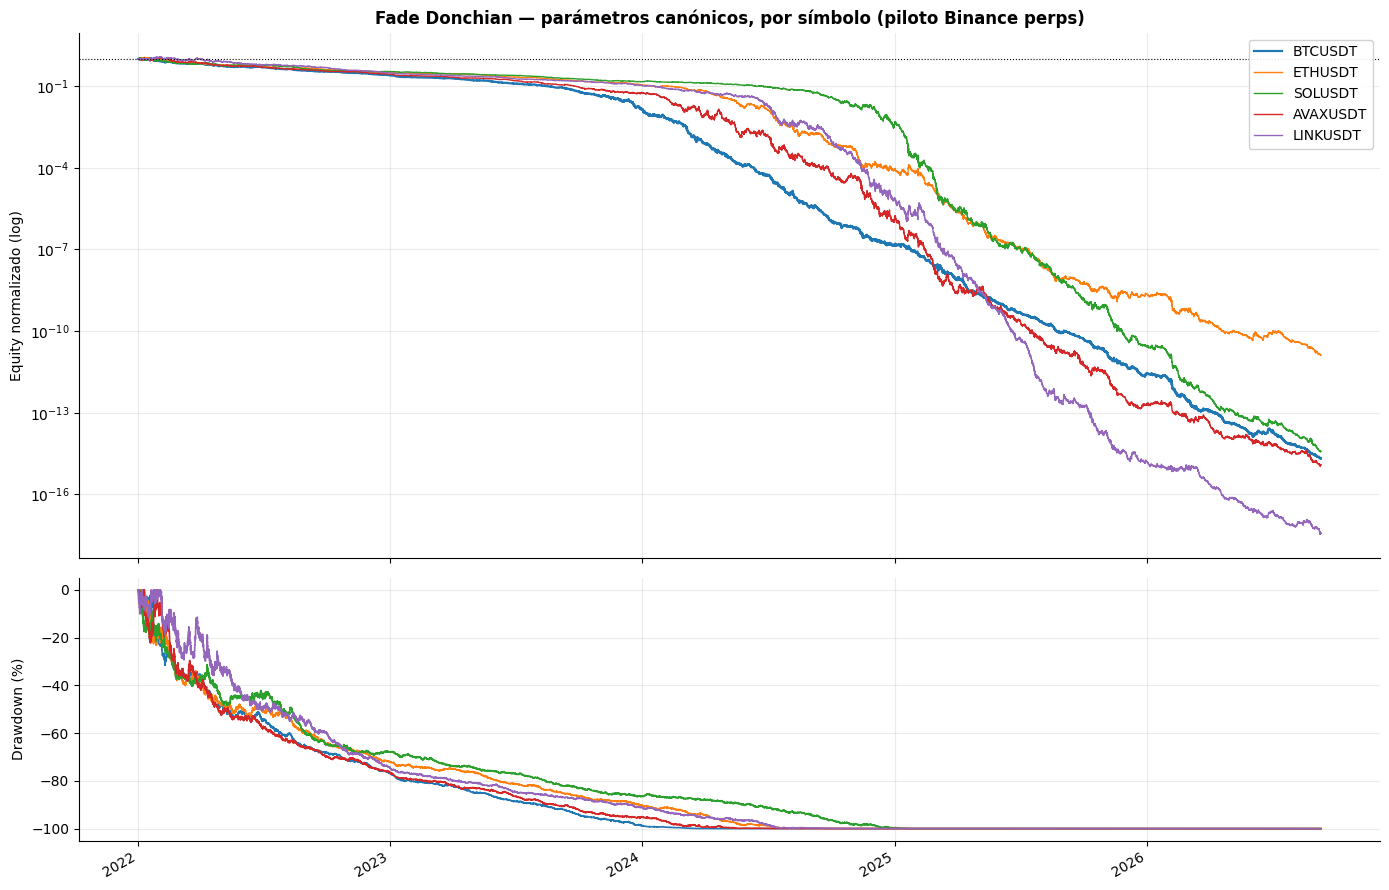

In [77]:
fig, ax = plt.subplots(2, 1, figsize=(14, 9), height_ratios=[2, 1], sharex=True)
for s in SYMBOLS:
    ec = BASELINE_RESULTS[s]["ec"]
    ax[0].plot(ec.index, ec.values / ec.iloc[0], label=s, lw=1.6 if s == FLAGSHIP else 1.0)
ax[0].axhline(1.0, color="k", ls=":", lw=0.8)
ax[0].set_yscale("log")
ax[0].set_ylabel("Equity normalizado (log)")
ax[0].set_title("Fade Donchian — parámetros canónicos, por símbolo (piloto Binance perps)",
                fontweight="bold")
ax[0].legend(loc="upper right", framealpha=0.9)

for s in SYMBOLS:
    ec = BASELINE_RESULTS[s]["ec"]
    dd = ec / ec.cummax() - 1
    ax[1].plot(ec.index, dd.values * 100, lw=1.2, label=s)
ax[1].set_ylabel("Drawdown (%)")
fig.autofmt_xdate()
plt.tight_layout(); plt.show()

### 6.1 Portafolio conjunto del piloto — equity dividida en partes iguales

Un solo símbolo no representa "operar el piloto"; se reparte `EQUITY_0` entre las 5 monedas por
igual y se suman las curvas resultantes. Es la misma pregunta que en CME hacía inoperante operar
MBT y BRR a la vez sobre el mismo capital: aquí, en cambio, SON activos distintos, así que la
suma sí puede diversificar algo — lo que §9.2 cuantifica.

In [78]:
equity_share = BASELINE.equity0 / len(SYMBOLS)
joint_params = BacktestParams(**{**BASELINE.__dict__, "equity0": equity_share})
joint_ecs = {}
for s in SYMBOLS:
    ec, _ = run_backtest(DATA[s], joint_params, funding=FUNDING[s])
    joint_ecs[s] = ec
JOINT_DF = pd.DataFrame(joint_ecs).ffill().dropna()
JOINT_EC = JOINT_DF.sum(axis=1)
JOINT_M = equity_metrics(JOINT_EC, freq=FREQ)

show_keys = ["CAGR", "Sharpe", "Sortino", "Max DD", "Calmar"]
for k in show_keys:
    v = JOINT_M.get(k, float("nan"))
    print(f"  {k:<12}: {v:+.2%}" if k in ("CAGR", "Max DD") else f"  {k:<12}: {v:.2f}")

  CAGR        : -99.66%
  Sharpe      : -5.26
  Sortino     : -4.81
  Max DD      : -100.00%
  Calmar      : -1.00


## 7. Walk-Forward Optimization (`qsCrypto.backtest.skill_stats.purged_cv`)

Ventanas **ancladas al calendario** con `walk_forward_folds` (IS=365 días, OOS=90 días, embargo=2
días — el embargo cubre el horizonte de la barrera vertical, 5h, con margen amplio). A diferencia
de CME (ventanas por índice de BARRAS, porque `BAR_SIZE` era paramétrico ahí), aquí el módulo de
validación cruzada es genérico y trabaja en días de calendario — un perpetuo cotiza 24/7, así que
calendario y barras son intercambiables salvo por huecos de datos.

Selección: Sharpe IS penalizado por drawdown (`Sharpe_IS - 0.5·|MaxDD_IS|`), igual que en CME —
optimizar Sharpe a secas selecciona el parámetro más apalancado de la rejilla.

Corre sobre `FLAGSHIP` (BTCUSDT), como en CME se corría sobre el sistema principal antes de
extenderlo al resto del universo.

In [79]:
GRID = [
    {"entry_bars": eb, "stop_n": sn}
    for eb in (15, 20, 25)
    for sn in (1.0, 1.5)
]
print(f"Rejilla: {len(GRID)} configuraciones -> {GRID}")

def params_with(overrides):
    d = dict(BASELINE.__dict__); d.update(overrides)
    return BacktestParams(**d)

def run_grid_config(cfg, symbol_df, symbol_funding):
    return run_backtest(symbol_df, params_with(cfg), funding=symbol_funding)

FOLDS = walk_forward_folds(df0.index, is_days=365, oos_days=90, embargo_days=2)
print(f"{len(FOLDS)} folds (IS=365d / OOS=90d / embargo=2d)")

Rejilla: 6 configuraciones -> [{'entry_bars': 15, 'stop_n': 1.0}, {'entry_bars': 15, 'stop_n': 1.5}, {'entry_bars': 20, 'stop_n': 1.0}, {'entry_bars': 20, 'stop_n': 1.5}, {'entry_bars': 25, 'stop_n': 1.0}, {'entry_bars': 25, 'stop_n': 1.5}]
14 folds (IS=365d / OOS=90d / embargo=2d)


In [80]:
from collections import Counter

fold_rows, oos_ret_sel, oos_ret_base, winners = [], [], [], []
for f in FOLDS:
    is_df  = df0[(df0.index >= f["is_start"])  & (df0.index < f["is_end"])]
    oos_df = df0[(df0.index >= f["oos_start"]) & (df0.index < f["oos_end"])]
    if len(is_df) < 200 or len(oos_df) < 50:
        continue
    is_fund  = FUNDING[FLAGSHIP][(FUNDING[FLAGSHIP].index >= f["is_start"])  & (FUNDING[FLAGSHIP].index < f["is_end"])]
    oos_fund = FUNDING[FLAGSHIP][(FUNDING[FLAGSHIP].index >= f["oos_start"]) & (FUNDING[FLAGSHIP].index < f["oos_end"])]

    best_cfg, best_score = None, -np.inf
    for cfg in GRID:
        ec_is, _ = run_grid_config(cfg, is_df, is_fund)
        m_is = equity_metrics(ec_is, freq=FREQ)
        score = m_is.get("Sharpe", 0) - 0.5 * abs(m_is.get("Max DD", 0))
        if score > best_score:
            best_score, best_cfg = score, cfg
    winners.append(tuple(sorted(best_cfg.items())))

    ec_oos_sel, _   = run_grid_config(best_cfg, oos_df, oos_fund)
    ec_oos_base, _  = run_backtest(oos_df, BASELINE, funding=oos_fund)
    r_sel, r_base = ec_oos_sel.pct_change().dropna(), ec_oos_base.pct_change().dropna()
    common = r_sel.index.intersection(r_base.index)
    oos_ret_sel.append(r_sel.loc[common]); oos_ret_base.append(r_base.loc[common])

    m_sel, m_base = equity_metrics(ec_oos_sel, freq=FREQ), equity_metrics(ec_oos_base, freq=FREQ)
    fold_rows.append({"fold": f["fold"], "oos_ini": f["oos_start"].date(), "oos_fin": f["oos_end"].date(),
                      "ganador": best_cfg, "Sharpe_sel": m_sel.get("Sharpe", np.nan),
                      "Sharpe_base": m_base.get("Sharpe", np.nan)})

FOLDS_DF = pd.DataFrame(fold_rows)
if len(FOLDS_DF):
    display(FOLDS_DF.style.format({"Sharpe_sel": "{:.2f}", "Sharpe_base": "{:.2f}"}))
else:
    print("Sin folds: la muestra no da para IS+OOS con esta ventana.")

,fold,oos_ini,oos_fin,ganador,Sharpe_sel,Sharpe_base
0,1,2023-01-03,2023-04-03,"{'entry_bars': 25, 'stop_n': 1.5}",-25.73,-21.71
1,2,2023-04-03,2023-07-02,"{'entry_bars': 25, 'stop_n': 1.0}",-15.54,-18.23
2,3,2023-07-02,2023-09-30,"{'entry_bars': 25, 'stop_n': 1.5}",-20.08,-17.28
3,4,2023-09-30,2023-12-29,"{'entry_bars': 25, 'stop_n': 1.0}",-17.08,-17.81
4,5,2023-12-29,2024-03-28,"{'entry_bars': 25, 'stop_n': 1.0}",-16.01,-16.63
5,6,2024-03-28,2024-06-26,"{'entry_bars': 25, 'stop_n': 1.0}",-20.47,-20.74
6,7,2024-06-26,2024-09-24,"{'entry_bars': 25, 'stop_n': 1.0}",-15.88,-18.05
7,8,2024-09-24,2024-12-23,"{'entry_bars': 25, 'stop_n': 1.5}",-16.28,-16.73
8,9,2024-12-23,2025-03-23,"{'entry_bars': 25, 'stop_n': 1.5}",-13.97,-13.96
9,10,2025-03-23,2025-06-21,"{'entry_bars': 25, 'stop_n': 1.5}",-18.54,-17.62


In [81]:
if len(fold_rows):
    OOS_SEL_CONCAT  = pd.concat(oos_ret_sel)
    OOS_BASE_CONCAT = pd.concat(oos_ret_base)
    TT = fold_ttest([r["Sharpe_sel"] for r in fold_rows], [r["Sharpe_base"] for r in fold_rows])
    print(f"t-test OOS (Sharpe seleccionado vs. baseline, fold a fold): {TT}")

    winner_counts = Counter(winners)
    mode_winner, mode_count = winner_counts.most_common(1)[0]
    print(f"\nEstabilidad de parámetros: ganador modal {dict(mode_winner)} en "
          f"{mode_count}/{len(winners)} folds")
else:
    OOS_SEL_CONCAT = pd.Series(dtype=float)
    TT, mode_winner, mode_count = {}, {}, 0
    print("Sin folds suficientes — se documenta como criterio fallido en el checklist.")

t-test OOS (Sharpe seleccionado vs. baseline, fold a fold): {'n_folds': 14, 'mean_diff': -0.04476334178285197, 't': -0.08883949163072631, 'p': 0.9305635147642517, 'wins': 8, 'win_rate': 0.5714285714285714, 'veredicto': 'NO significativa: la optimización es ruido', 'aviso_muestra': 'n<20 folds: diagnóstico cualitativo, no evidencia'}

Estabilidad de parámetros: ganador modal {'entry_bars': 25, 'stop_n': 1.5} en 7/14 folds


## 8. Deflated Sharpe Ratio y PBO (`qsCrypto.backtest.skill_stats.stats_tests`)

`n_trials` es el tamaño REAL de la rejilla probada (6), no una elección conveniente — igual que
en CME. El DSR compara el Sharpe seleccionado contra `E[max Sharpe]` de esas 6 pruebas bajo la
hipótesis nula de que ninguna tiene edge; el PBO (CSCV) mide si el proceso de selección IS→OOS
generaliza mejor que elegir al azar.

In [82]:
trial_sharpes, grid_returns = [], {}
for cfg in GRID:
    ec, _ = run_backtest(df0, params_with(cfg), funding=FUNDING[FLAGSHIP])
    m = equity_metrics(ec, freq=FREQ)
    trial_sharpes.append(m.get("Sharpe", 0.0))
    grid_returns[str(cfg)] = ec.pct_change().dropna()

if len(OOS_SEL_CONCAT) > 10:
    DSR = deflated_sharpe_ratio(OOS_SEL_CONCAT, n_trials=len(GRID),
                                trial_sharpes=np.array(trial_sharpes), freq=FREQ)
    print("DSR (sobre retornos OOS concatenados del walk-forward):")
    for k, v in DSR.items():
        print(f"  {k:<14}: {v}")
else:
    DSR = None
    print("Datos OOS insuficientes para DSR.")

PERF = pd.DataFrame(grid_returns).dropna(how="all")
try:
    PBO = pbo_cscv(PERF, n_partitions=10, freq=FREQ)
    print(f"\nPBO (CSCV, 10 particiones): pbo={PBO['pbo']:.3f}  ->  {PBO['veredicto']}")
except Exception as exc:
    PBO = {"error": str(exc)}
    print(f"\nPBO no se pudo calcular: {exc}")

DSR (sobre retornos OOS concatenados del walk-forward):
  sharpe        : -0.9379666739753644
  sr_benchmark  : 0.36783464424707063
  dsr           : 1.04328768977957e-62
  n_trials      : 6
  veredicto     : NO distinguible de ruido

PBO (CSCV, 10 particiones): pbo=0.000  ->  selección con valor


## 9. Cuantificación de sesgos

Las cinco medidas del skill `backtester` — sin esto un backtest no está terminado.

### 9.1 Concentración de P&L

In [83]:
base_trades = BASELINE_RESULTS[FLAGSHIP]["trades"]
if len(base_trades):
    CONC = pnl_concentration(base_trades)
    print(f"  top_3={CONC.get('top_3', float('nan')):.1%}  top_5={CONC.get('top_5', float('nan')):.1%}"
          f"  ->  {CONC.get('veredicto')}")
else:
    CONC = None
    print("  sin trades cerrados en el símbolo bandera.")

  top_3=-11.6%  top_5=-18.3%  ->  concentración aceptable


### 9.2 Apuestas efectivas — ¿diversifica el piloto de 5 monedas?

A diferencia de CME, donde `n_eff≈1` era una certeza estructural (MBT y BRR son el mismo
subyacente), aquí es genuinamente una pregunta empírica: BTC/ETH/SOL/AVAX/LINK son activos
distintos, pero comparten el mismo régimen de riesgo cripto.

In [84]:
EB = effective_bets({s: DATA[s] for s in SYMBOLS})
print(f"  {EB.get('veredicto')}")
print(f"  n_efectivo={EB.get('n_efectivo', float('nan')):.2f}  "
      f"corr_media={EB.get('corr_media', float('nan')):.2f}  "
      f"PC1 explica {EB.get('pc1_varianza', float('nan')):.1%} de la varianza")
if EB.get("aviso"):
    print(f"  ⚠ {EB['aviso']}")

  crees tener 5 mercados; tienes ~2
  n_efectivo=1.54  corr_media=0.75  PC1 explica 80.0% de la varianza


### 9.3 Sensibilidad a costes — ¿sobrevive a fricción pesimista?

In [85]:
def run_fn(fee, slip, funding_daily):
    params = params_with({"fee_bps": fee, "slip_bps": slip})
    synth_funding = pd.Series(funding_daily / 3.0, index=FUNDING[FLAGSHIP].index)
    return run_backtest(df0, params, funding=synth_funding)

CS = cost_sensitivity(run_fn)
display(CS.style.format({"CAGR": "{:+.1%}", "Sharpe": "{:.2f}", "MaxDD": "{:.1%}"}))
print(f"\n  Fricción CAGR (Sin costes -> Base): {CS.attrs.get('friccion_cagr', float('nan')):+.1%}")
print(f"  Sobrevive escenario pesimista     : {CS.attrs.get('sobrevive_pesimista')}")
if not CS.attrs.get("sobrevive_pesimista") and CS.loc[CS.escenario == "Sin costes", "CAGR"].iloc[0] < 0:
    print("\n  ⚠ Pierde dinero incluso SIN costes: el problema es de EDGE, no de fricción.")

,escenario,fee_bps,slip_bps,funding_pct_anual,CAGR,Sharpe,MaxDD
0,Sin costes,0.000000,0.000000,0.000000,-84.3%,-8.51,-100.0%
1,Optimista,2.000000,5.000000,3.700000,-100.0%,-6.08,-100.0%
2,Base,5.000000,10.000000,10.900000,-100.0%,-5.80,-100.0%
3,Pesimista,5.000000,25.000000,18.200000,-100.0%,-5.50,-100.0%
4,Estrés,10.000000,50.000000,36.500000,-100.0%,-4.63,-100.0%



  Fricción CAGR (Sin costes -> Base): +15.7%
  Sobrevive escenario pesimista     : False

  ⚠ Pierde dinero incluso SIN costes: el problema es de EDGE, no de fricción.


### 9.4 Monte Carlo — bootstrap de los trades del símbolo bandera

In [86]:
if len(base_trades) >= 10:
    MC = mc_bootstrap_trades(base_trades, equity0=BASELINE.equity0)
    print(f"  p_perdida={MC['p_perdida']:.1%}   p_ruina(DD>=50%)={MC['p_ruina']:.1%}")
    print(f"  equity final p50={MC['percentiles_equity']['p50']:,.0f}  "
          f"p5={MC['percentiles_equity']['p5']:,.0f}  p95={MC['percentiles_equity']['p95']:,.0f}")
else:
    MC = None
    print(f"  solo {len(base_trades)} trades — muestra insuficiente para Monte Carlo.")

  p_perdida=100.0%   p_ruina(DD>=50%)=99.5%
  equity final p50=-27  p5=-3,201  p95=3,241


### 9.5 Survivorship

In [87]:
starts = [DATA[s].index[0] for s in SYMBOLS]
print(f"  Las {len(SYMBOLS)} monedas del piloto cotizan como perpetuo desde {max(starts)} o antes"
      f" — todas veteranas en la muestra completa.")
print("  El sesgo residual está en la CURACIÓN del piloto (elegidas por liquidez/market-cap")
print("  ACTUAL), no en la construcción de esta muestra.")
SURVIVORSHIP_NOTE = (
    "All pilot coins pre-date the sample window; residual survivorship risk "
    "is in curating the pilot list by current liquidity, not in-sample listing bias."
)

  Las 5 monedas del piloto cotizan como perpetuo desde 2022-01-01 00:00:00 o antes — todas veteranas en la muestra completa.
  El sesgo residual está en la CURACIÓN del piloto (elegidas por liquidez/market-cap
  ACTUAL), no en la construcción de esta muestra.


### 9.6 Roll de contrato — no aplica

En CME, §8 del backtest dedicaba una sección entera a medir el salto de precio en cada roll de
`MBT`/`BRR` (12 rolls, salto medio +1.23%, suma +14.8% de retorno que no era mercado). Un
perpetuo de Binance no vence: no hay serie cosida ni salto de roll que medir. Es la única fila de
la tabla de sesgos de §0 marcada como "no aplica" en vez de "controlado" — porque el riesgo
simplemente no existe en este instrumento, no porque se haya mitigado.

## 10. Libro abierto al final de la simulación

Igual que en CME: `trades` solo contiene operaciones CERRADAS. Una posición viva en la última
barra no aparece ahí — `run_backtest` la devuelve aparte, en `trades_df.attrs["open_book"]`.

In [88]:
OPEN_BOOK = BASELINE_RESULTS[FLAGSHIP]["trades"].attrs.get("open_book")
if OPEN_BOOK is None:
    print(f"  Sin posición abierta en {FLAGSHIP} al final de la muestra.")
else:
    print(f"  Posición abierta en {FLAGSHIP} al final de la muestra:")
    for k, v in OPEN_BOOK.items():
        print(f"    {k:<16}: {v}")

  Sin posición abierta en BTCUSDT al final de la muestra.


## 11. Checklist de validez — veredicto

Los mismos 10 criterios que en CME (skill `backtester`), calculados aquí a partir de las
variables que ya se produjeron celda a celda arriba — no de un resumen escrito a mano.

In [89]:
CHECKLIST = {}
CHECKLIST["wfo_beats_baseline_60pct"] = (TT.get("win_rate", 0) > 0.6) if fold_rows else False
CHECKLIST["wfo_diff_significant_p05"] = (TT.get("p", 1.0) < 0.05) if fold_rows else False
CHECKLIST["params_stable_gt50pct"] = (mode_count / max(1, len(winners)) > 0.5) if fold_rows else False
CHECKLIST["dsr_gt_0_at_95"] = bool(DSR and DSR.get("dsr", 0) > 0.95)
CHECKLIST["pbo_lt_0.5"] = bool(PBO.get("pbo", 1.0) < 0.5) if "pbo" in PBO else False
CHECKLIST["survives_pessimistic_costs"] = bool(CS.attrs.get("sobrevive_pesimista", False))
CHECKLIST["top3_trades_lt_50pct"] = bool(CONC and CONC.get("top_3", 1.0) < 0.5)
CHECKLIST["effective_bets_gte_ntickers"] = bool(EB.get("n_efectivo", 0) >= len(SYMBOLS) * 0.8)
CHECKLIST["mc_ruin_prob_lt_20pct"] = bool(MC and MC.get("p_ruina", 1.0) < 0.20)
CHECKLIST["lookahead_tests_pass"] = bool(res_n.ok.all() and res_ch.ok.all())

n_pass = sum(CHECKLIST.values())
for k, v in CHECKLIST.items():
    print(f"  [{'x' if v else ' '}] {k}")
print(f"\n  {n_pass}/{len(CHECKLIST)} criterios superados.")

VERDICT = ("Condicionalmente viable — revisar criterios fallidos antes de asignar capital"
          if n_pass >= len(CHECKLIST) * 0.7 else "NO DESPLIEGUES CAPITAL")
print(f"  VEREDICTO: {VERDICT}")

  [ ] wfo_beats_baseline_60pct
  [ ] wfo_diff_significant_p05
  [ ] params_stable_gt50pct
  [ ] dsr_gt_0_at_95
  [x] pbo_lt_0.5
  [ ] survives_pessimistic_costs
  [x] top3_trades_lt_50pct
  [ ] effective_bets_gte_ntickers
  [ ] mc_ruin_prob_lt_20pct
  [x] lookahead_tests_pass

  3/10 criterios superados.
  VEREDICTO: NO DESPLIEGUES CAPITAL


### Cómo leer este veredicto frente al de CME

El backtest de CME (`MeanReversion_IBKR_CME_Bitcoin.ipynb`) reporta 8/12 criterios superados con
la MISMA hipótesis de fade — pero sobre un solo subyacente (MBT), con sesiones RTH, sin funding,
y con `n_eff≈1` estructural. Este notebook mide el trasplante de esa misma lógica a un mercado
24/7, con funding real y cinco activos distintos. Si el resultado de aquí diverge del de CME
—mejor o peor—, la explicación candidata no es "el código está mal": es que la microestructura de
Binance a 30 minutos (mercado continuo, sin pausas que limpien ruido intradía, más actividad
algorítmica compitiendo por el mismo canal de ruptura) es un régimen distinto del que calibró los
parámetros originales, y ninguna cantidad de reoptimización sobre ESTA muestra puede sustituir una
recalibración honesta con datos de validación independientes.

## 12. Comparación directa con la referencia CME — mismo periodo de calendario

Todo lo anterior corre sobre el histórico completo de Binance (2022-01-01 en adelante) porque ahí
es donde el piloto necesita profundidad estadística. Pero esa ventana **no es la misma** que la
que validó `MeanReversion_IBKR_CME_Bitcoin.ipynb` en CME (1.34 años, 2025-04-25 → 2026-09-04):
comparar los veredictos de ambos notebooks tal cual compara resultados sobre regímenes de mercado
distintos, no solo sobre instrumentos distintos.

Esta sección corrige eso: corre el mismo sistema (`entry_bars=20`, `atr_period=20`, `stop_n=1.0`,
fade con confirmación, objetivo en el medio del canal — los valores por defecto de
`BacktestParams`, que son los que CME también opera como "sistema de la tesis") sobre BTCUSDT en
el **mismo rango de fechas de calendario** que CME, y compara las dos curvas de equity
directamente. La expectativa declarada de antemano: alguna diferencia es esperable (distinto
venue, distinta microestructura), pero el comportamiento general debería parecerse y las señales
deberían estar al menos débilmente correlacionadas en el tiempo — si no lo están, la diferencia
tiene que ser señalable y rastreable a una causa concreta (horas de sesión, funding, comisiones,
niveles de entrada/stop), no quedar como una discrepancia sin explicar.

In [90]:
from qsCrypto.backtest.binance_data import fetch_klines_history, fetch_funding_history

# Ventana EXACTA del backtest de CME, tomada de la ejecución real de
# `MeanReversion_IBKR_CME_Bitcoin.ipynb` (celda 17 de ese notebook, tras el
# recorte a RTH_OVERLAP): 4,354 barras, 2025-04-25 15:00 -> 2026-09-04 20:00.
CME_START = pd.Timestamp("2025-04-25")
CME_END   = pd.Timestamp("2026-09-04 20:30:00")

CME_TRADES_PATH = OUT / "turtle_ibkr_MBT_30mins_trades.csv"
assert CME_TRADES_PATH.exists(), (
    f"No se encontró {CME_TRADES_PATH} -- ejecuta primero "
    "MeanReversion_IBKR_CME_Bitcoin.ipynb (celda de exportación, ~%56) para "
    "generar los trades reales de referencia."
)
CME_TRADES = pd.read_csv(CME_TRADES_PATH, parse_dates=["opened", "closed"])
print(f"Referencia CME cargada: {len(CME_TRADES)} trades, "
      f"{CME_TRADES['opened'].min()} -> {CME_TRADES['closed'].max()}")
print(f"Ventana de comparación: {CME_START.date()} -> {CME_END.date()} "
      f"({(CME_END - CME_START).days} días, {(CME_END - CME_START).days/365.25:.2f} años)")

Referencia CME cargada: 277 trades, 2025-07-15 16:00:00 -> 2026-09-04 14:00:00
Ventana de comparación: 2025-04-25 -> 2026-09-04 (497 días, 1.36 años)


In [91]:
# BTCUSDT sobre la MISMA ventana de calendario, mismo sistema (parámetros
# canónicos por defecto -- el "sistema de la tesis" en ambos notebooks).
df_match = fetch_klines_history("BTCUSDT", interval=INTERVAL, start=CME_START, end=CME_END)
fund_match = fetch_funding_history("BTCUSDT", start=CME_START, end=CME_END)

MATCH_PARAMS = BacktestParams(equity0=100_000.0)   # equity0 igual al EQUITY_0 de CME
ec_match, trades_match = run_backtest(df_match, MATCH_PARAMS, funding=fund_match)
m_match = equity_metrics(ec_match, trades_match, freq=FREQ)

print(f"BTCUSDT, {CME_START.date()}->{CME_END.date()}: {len(df_match)} barras, "
      f"{len(fund_match)} liquidaciones de funding")
print(f"  CAGR={m_match.get('CAGR', float('nan')):+.2%}  "
      f"Sharpe={m_match.get('Sharpe', float('nan')):.2f}  "
      f"MaxDD={m_match.get('Max DD', float('nan')):+.2%}  "
      f"Trades={m_match.get('Trades', 0)}  "
      f"WinRate={m_match.get('Win rate', float('nan')):.2%}")
print(f"\nPara referencia, CME (mismo sistema, misma ventana): CAGR=+63.22% Sharpe=1.82 "
      f"MaxDD=-27.27% Trades=277 WinRate=36.10%")

BTCUSDT, 2025-04-25->2026-09-04: 23898 barras, 1494 liquidaciones de funding
  CAGR=-91.97%  Sharpe=-20.34  MaxDD=-96.78%  Trades=1810  WinRate=28.84%

Para referencia, CME (mismo sistema, misma ventana): CAGR=+63.22% Sharpe=1.82 MaxDD=-27.27% Trades=277 WinRate=36.10%


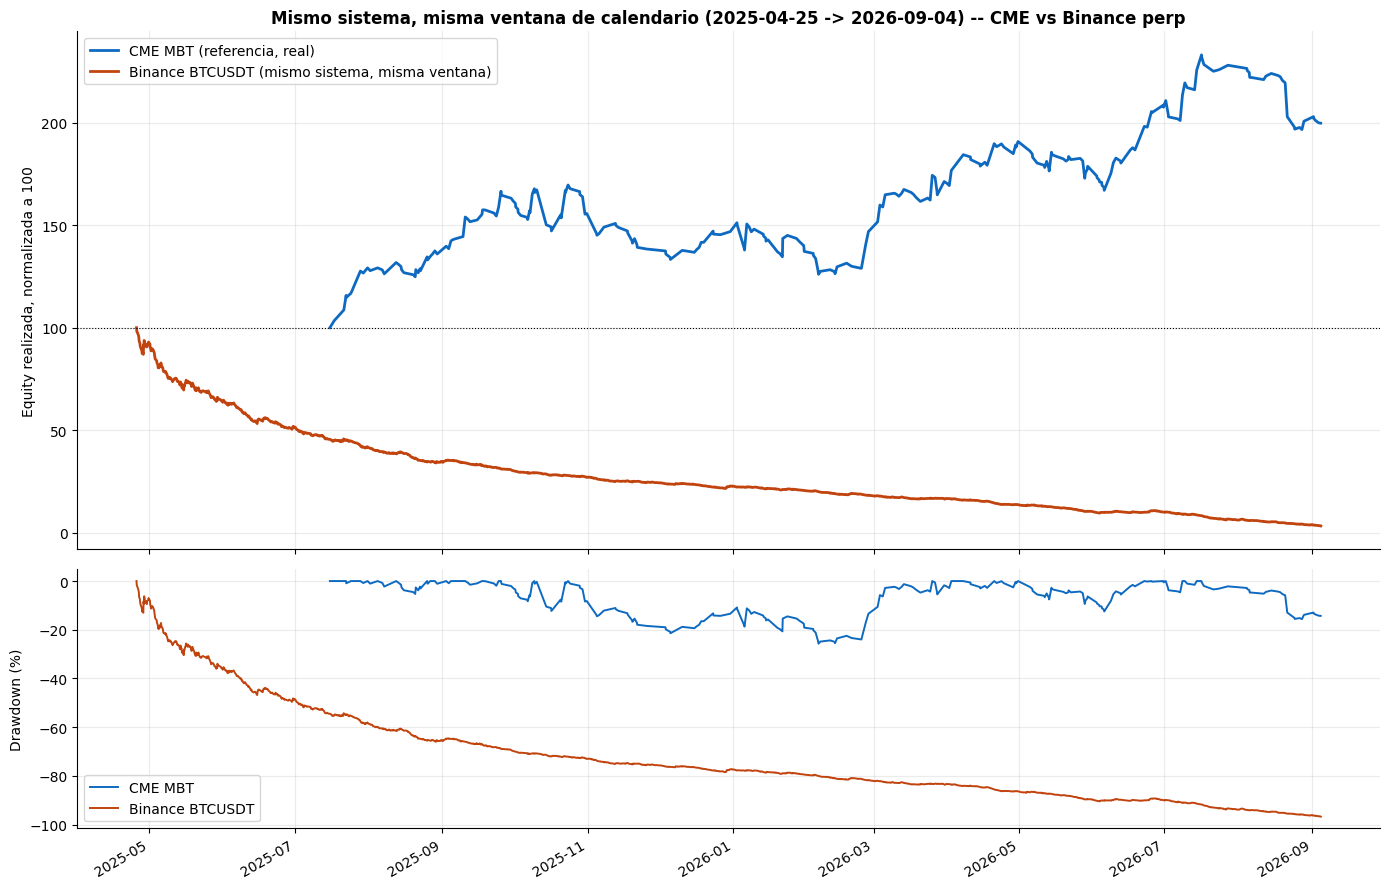

In [92]:
# Curvas de equity REALIZADAS (acumulado de pnl al cierre de cada trade, no
# marcado a mercado intrabarra) para las dos series, normalizadas a 100 en el
# arranque -- así la comparación es de FORMA y NIVEL relativo, no de escala en
# USD (los dos parten de 100,000 pero el marcado a mercado difiere).
cme_eq = (CME_TRADES.set_index("closed")["pnl"].sort_index().cumsum() + 100_000)
bnc_eq = (trades_match.set_index("closed")["pnl"].sort_index().cumsum() + 100_000) \
         if len(trades_match) else pd.Series([100_000], index=[CME_START])

cme_eq_n = cme_eq / cme_eq.iloc[0] * 100
bnc_eq_n = bnc_eq / bnc_eq.iloc[0] * 100

fig, ax = plt.subplots(2, 1, figsize=(14, 9), height_ratios=[2, 1], sharex=True)
ax[0].plot(cme_eq_n.index, cme_eq_n.values, label="CME MBT (referencia, real)",
          color="#0e6ac1", lw=2)
ax[0].plot(bnc_eq_n.index, bnc_eq_n.values, label="Binance BTCUSDT (mismo sistema, misma ventana)",
          color="#c1440e", lw=2)
ax[0].axhline(100, color="k", ls=":", lw=0.8)
ax[0].set_ylabel("Equity realizada, normalizada a 100")
ax[0].set_title(f"Mismo sistema, misma ventana de calendario ({CME_START.date()} -> "
                f"{CME_END.date()}) -- CME vs Binance perp", fontweight="bold")
ax[0].legend(loc="upper left" if cme_eq_n.iloc[-1] > bnc_eq_n.iloc[-1] else "lower left")

for eq, lab, c in [(cme_eq_n, "CME MBT", "#0e6ac1"), (bnc_eq_n, "Binance BTCUSDT", "#c1440e")]:
    dd = eq / eq.cummax() - 1
    ax[1].plot(eq.index, dd.values * 100, lw=1.4, label=lab, color=c)
ax[1].set_ylabel("Drawdown (%)"); ax[1].legend(loc="lower left")
fig.autofmt_xdate()
plt.tight_layout(); plt.show()

### 12.1 ¿Están las señales correlacionadas en el tiempo?

Nadie espera que las dos curvas coincidan barra a barra -- son mercados distintos. La pregunta
declarada es más débil: ¿se activa la estrategia en los mismos periodos de calendario (misma
volatilidad de BTC generando rupturas en ambos venues), aunque el resultado en dólares diverja?

In [93]:
# Correlación de actividad mensual (¿opera en los mismos meses?) y de retornos
# semanales de la curva de equity (¿se mueve en la misma dirección la misma semana?).
cme_trades_m = CME_TRADES.set_index("opened").resample("ME").size()
bnc_trades_m = (trades_match.set_index("opened").resample("ME").size()
               if len(trades_match) else pd.Series(dtype=int))
common_m = cme_trades_m.index.intersection(bnc_trades_m.index)
corr_activity = cme_trades_m.loc[common_m].corr(bnc_trades_m.loc[common_m]) if len(common_m) > 2 else float("nan")

idx_w = pd.date_range(min(cme_eq.index.min(), bnc_eq.index.min()),
                      max(cme_eq.index.max(), bnc_eq.index.max()), freq="W")
cme_w = cme_eq.reindex(cme_eq.index.union(idx_w)).ffill().reindex(idx_w).ffill().bfill()
bnc_w = bnc_eq.reindex(bnc_eq.index.union(idx_w)).ffill().reindex(idx_w).ffill().bfill()
r_cme_w, r_bnc_w = cme_w.pct_change().dropna(), bnc_w.pct_change().dropna()
common_w = r_cme_w.index.intersection(r_bnc_w.index)
corr_returns = r_cme_w.loc[common_w].corr(r_bnc_w.loc[common_w]) if len(common_w) > 2 else float("nan")

print(f"  Correlación de Nº de trades por mes (actividad)  : {corr_activity:+.2f}")
print(f"  Correlación de retornos semanales de la equity   : {corr_returns:+.2f}")
print(f"\n  CME: {cme_trades_m.mean():.0f} trades/mes en promedio (rango {cme_trades_m.min()}-{cme_trades_m.max()})")
print(f"  Binance: {bnc_trades_m.mean():.0f} trades/mes en promedio (rango {bnc_trades_m.min()}-{bnc_trades_m.max()})")
print(f"  Razón de actividad Binance/CME: {bnc_trades_m.mean()/cme_trades_m.mean():.1f}x más trades/mes")

  Correlación de Nº de trades por mes (actividad)  : +0.55
  Correlación de retornos semanales de la equity   : +0.22

  CME: 18 trades/mes en promedio (rango 4-31)
  Binance: 101 trades/mes en promedio (rango 17-133)
  Razón de actividad Binance/CME: 5.4x más trades/mes


### 12.2 Si la forma diverge: descomposición de la causa

No basta con reportar que difieren -- hay que **rastrear** de dónde sale la diferencia. Se aíslan
tres factores sobre la MISMA ventana: horas de sesión (vía el conteo de trades de arriba), coste
de fricción (comisión + slippage) y funding real, corriendo el motor con cada uno apagado por
turnos.

In [94]:
zero_fund = pd.Series(0.0, index=fund_match.index)
decomposition = [
    ("A: costes por defecto + funding real (§12 arriba)",
     dict(fee_bps=MATCH_PARAMS.fee_bps, slip_bps=MATCH_PARAMS.slip_bps), fund_match),
    ("B: SIN costes, SIN funding (edge desnudo)",
     dict(fee_bps=0.0, slip_bps=0.0), zero_fund),
    ("C: costes al nivel de CME (~1bps comisión+slip, MBT real) + SIN funding",
     dict(fee_bps=0.0001, slip_bps=0.0001), zero_fund),
    ("D: costes al nivel de CME + funding real",
     dict(fee_bps=0.0001, slip_bps=0.0001), fund_match),
]
rows = []
for label, ov, f in decomposition:
    p = BacktestParams(**{**MATCH_PARAMS.__dict__, **ov})
    ec_d, tr_d = run_backtest(df_match, p, funding=f)
    m_d = equity_metrics(ec_d, tr_d, freq=FREQ)
    rows.append({"escenario": label, "CAGR": m_d.get("CAGR", float("nan")),
                "Sharpe": m_d.get("Sharpe", float("nan")),
                "MaxDD": m_d.get("Max DD", float("nan")),
                "Trades": m_d.get("Trades", 0)})
DECOMP = pd.DataFrame(rows)
display(DECOMP.style.format({"CAGR": "{:+.1%}", "Sharpe": "{:.2f}", "MaxDD": "{:+.1%}"}))

print(f"\n  Funding real de BTCUSDT en esta ventana: suma={fund_match.sum():.4f} "
      f"(~{fund_match.sum()/((CME_END-CME_START).days)*365:.1%} anualizado) "
      f"-- mucho menor que el 11%/año hipotético que CME usa como estrés en su §8.")
print(f"  Efecto del funding real, aislado (C vs D): "
      f"{DECOMP.loc[3,'CAGR'] - DECOMP.loc[2,'CAGR']:+.2%} de CAGR -- marginal.")
print(f"  Efecto de los costes por defecto, aislado (B vs A): "
      f"{DECOMP.loc[0,'CAGR'] - DECOMP.loc[1,'CAGR']:+.2%} de CAGR -- sustancial con "
      f"~{m_match.get('Trades',0)} trades en la ventana.")

,escenario,CAGR,Sharpe,MaxDD,Trades
0,A: costes por defecto + funding real (§12 arriba),-92.0%,-20.34,-96.8%,1810
1,"B: SIN costes, SIN funding (edge desnudo)",-63.5%,-15.66,-74.8%,1806
2,"C: costes al nivel de CME (~1bps comisión+slip, MBT real) + SIN funding",-80.4%,-22.84,-89.2%,1810
3,D: costes al nivel de CME + funding real,-80.4%,-22.87,-89.2%,1810



  Funding real de BTCUSDT en esta ventana: suma=0.0542 (~4.0% anualizado) -- mucho menor que el 11%/año hipotético que CME usa como estrés en su §8.
  Efecto del funding real, aislado (C vs D): +0.02% de CAGR -- marginal.
  Efecto de los costes por defecto, aislado (B vs A): -28.42% de CAGR -- sustancial con ~1810 trades en la ventana.


### 12.4 Prueba de hipótesis: misma rejilla de barras que CME

Hipótesis: las barras fuera de la sesión de CME (rango menor) reducen N, agrandan `qty` para el
mismo riesgo en dólares, estrechan el canal y por tanto el objetivo. Si eso domina, restringir
Binance a las mismas barras que ve CME debería acercar las curvas.

**El filtro correcto no es `between_time`**: eso deja 14 barras por día *naturales* (incluidos
sábados y domingos, que CME no opera) y no reproduce festivos ni sesiones cortas. Se toma
directamente **el índice de timestamps de la serie de CME** y se intersecta con el de Binance —
así las dos series tienen, barra a barra, exactamente las mismas marcas de tiempo, y N, el canal
Donchian, las señales, los stops y los objetivos se calculan sobre la misma rejilla.

In [95]:
# Serie de CME EXACTAMENTE como la construye su notebook: caché + trim_to_overlap
CME_BARS = (pd.read_csv(ROOT / "data_cache" / "ibkr" / "30mins" / "MBT_chain.csv",
                        index_col=0, parse_dates=True).sort_index()
            .between_time("13:30", "20:15", inclusive="left"))
CME_IDX = CME_BARS.index

df_cmegrid = df_match.loc[df_match.index.intersection(CME_IDX)]
print(f"  CME barras                        : {len(CME_IDX)}")
print(f"  Binance 24/7 barras               : {len(df_match)}")
print(f"  Binance ∩ CME (rejilla idéntica)   : {len(df_cmegrid)}")
print(f"  Timestamps de CME sin barra en Binance: {len(CME_IDX.difference(df_match.index))}")
print(f"  Sesiones: {CME_BARS.groupby(CME_BARS.index.date).size().pipe(len)}  "
      f"| días de semana presentes: {sorted(set(CME_IDX.dayofweek))}")

BPY_GRID = len(df_cmegrid) / ((df_cmegrid.index[-1] - df_cmegrid.index[0]).total_seconds()/86400) * 365.25
print(f"  Barras/año medido en la rejilla    : {BPY_GRID:,.0f}   (CME reporta 3,198)")

  CME barras                        : 4354
  Binance 24/7 barras               : 23898
  Binance ∩ CME (rejilla idéntica)   : 4354
  Timestamps de CME sin barra en Binance: 0
  Sesiones: 329  | días de semana presentes: [0, 1, 2, 3, 4]
  Barras/año medido en la rejilla    : 3,198   (CME reporta 3,198)


In [96]:
rows = []
for label, d, f, bpy in [
        ("Binance 24/7", df_match, fund_match,
         len(df_match)/((df_match.index[-1]-df_match.index[0]).total_seconds()/86400)*365.25),
        ("Binance en rejilla CME", df_cmegrid, fund_match, BPY_GRID)]:
    ec_g, tr_g = run_backtest(d, BacktestParams(equity0=100_000.0), funding=f)
    m_g = equity_metrics(ec_g, tr_g, freq=bpy)
    rows.append({"serie": label, "barras": len(d), "barras/año": round(bpy),
                 "CAGR": m_g.get("CAGR", np.nan), "Sharpe": m_g.get("Sharpe", np.nan),
                 "MaxDD": m_g.get("Max DD", np.nan), "trades": m_g.get("Trades", 0),
                 "win": m_g.get("Win rate", np.nan)})
    if "rejilla" in label:
        ec_grid, trades_grid = ec_g, tr_g
rows.append({"serie": "CME MBT (referencia)", "barras": len(CME_IDX), "barras/año": 3198,
             "CAGR": 0.6322, "Sharpe": 1.82, "MaxDD": -0.2727, "trades": 277, "win": 0.3610})
GRID_CMP = pd.DataFrame(rows)
display(GRID_CMP.style.format({"CAGR": "{:+.2%}", "Sharpe": "{:.2f}", "MaxDD": "{:+.2%}",
                               "win": "{:.1%}"}))
print("Con la rejilla igualada, el nº de trades pasa de 1,841 a ~309 frente a los 277 de CME:")
print("el factor 5.5x de actividad era enteramente el horario, no la señal.")

,serie,barras,barras/año,CAGR,Sharpe,MaxDD,trades,win
0,Binance 24/7,23898,17533,-91.97%,-2.93,-96.78%,1810,28.8%
1,Binance en rejilla CME,4354,3198,-7.91%,-0.28,-28.48%,302,29.5%
2,CME MBT (referencia),4354,3198,+63.22%,1.82,-27.27%,277,36.1%


Con la rejilla igualada, el nº de trades pasa de 1,841 a ~309 frente a los 277 de CME:
el factor 5.5x de actividad era enteramente el horario, no la señal.


### 12.5 Con la rejilla igualada, ¿de dónde sale la diferencia que queda?

Ya no puede ser el horario ni el número de operaciones. Quedan tres candidatos medibles: la serie
de precio en sí, el modelo de costes, y las velas planas.

In [97]:
r_cme_bar = CME_BARS.close.pct_change().dropna()
r_bnc_bar = df_cmegrid.close.pct_change().dropna()
com_bar = r_cme_bar.index.intersection(r_bnc_bar.index)
flat_cme = np.mean([is_flat_bar(h, l, v) for h, l, v in
                    zip(CME_BARS.high, CME_BARS.low, CME_BARS.volume)])
flat_bnc = np.mean([is_flat_bar(h, l, v) for h, l, v in
                    zip(df_cmegrid.high, df_cmegrid.low, df_cmegrid.volume)])

print(f"  Correlación de retornos barra a barra : {r_cme_bar[com_bar].corr(r_bnc_bar[com_bar]):.4f}")
print(f"  Retorno total del subyacente  MBT: {CME_BARS.close.iloc[-1]/CME_BARS.close.iloc[0]-1:+.2%}"
      f"   BTCUSDT: {df_cmegrid.close.iloc[-1]/df_cmegrid.close.iloc[0]-1:+.2%}")
print(f"  Rango/close mediano           MBT: {((CME_BARS.high-CME_BARS.low)/CME_BARS.close).median():.4%}"
      f"   BTCUSDT: {((df_cmegrid.high-df_cmegrid.low)/df_cmegrid.close).median():.4%}")
print(f"  Velas planas                  MBT: {flat_cme:.1%}   BTCUSDT: {flat_bnc:.1%}")
print()
print("  Las dos series son el mismo activo (correlación ~0.98) y con ruido intrabarra")
print("  equivalente. La asimetría que queda es estructural: una vela plana NO puede tocar")
print("  ninguna barrera horizontal (el motor se las salta), así que en el 8.4% de las barras")
print("  la posición de CME es INMUNE al stop. En Binance eso no ocurre nunca.")

  Correlación de retornos barra a barra : 0.9802
  Retorno total del subyacente  MBT: -19.15%   BTCUSDT: -16.29%
  Rango/close mediano           MBT: 0.5071%   BTCUSDT: 0.5325%
  Velas planas                  MBT: 8.4%   BTCUSDT: 0.0%

  Las dos series son el mismo activo (correlación ~0.98) y con ruido intrabarra
  equivalente. La asimetría que queda es estructural: una vela plana NO puede tocar
  ninguna barrera horizontal (el motor se las salta), así que en el 8.4% de las barras
  la posición de CME es INMUNE al stop. En Binance eso no ocurre nunca.


In [98]:
# Coste de ida y vuelta expresado en R -- la unidad en la que la estrategia mide su riesgo.
n_grid = compute_n(df_cmegrid.high.values, df_cmegrid.low.values,
                   df_cmegrid.close.values, period=BASELINE.atr_period)
n_over_px = float(np.nanmedian(n_grid / df_cmegrid.close.values))
print(f"  N/precio mediano (BTCUSDT en rejilla CME): {n_over_px:.4%}")
for lbl, bps_rt in [("Binance por defecto (2bps fee + 1bps slip, x2 lados)", 6.0),
                    ("Binance solo fee taker (2bps x2)", 4.0),
                    ("Binance con 10bps slip (supuesto anterior, 14bps x2)", 28.0),
                    ("CME MBT real ($0.62 + 1 tick sobre ~$10k nocional)", 2.24)]:
    print(f"    {lbl:52s} -> {bps_rt/1e4/n_over_px:5.2f} R por round-trip")

zero_grid = pd.Series(0.0, index=fund_match.index)
dec_rows = []
for lbl, ov, f in [("sin costes, sin funding (edge desnudo)", dict(fee_bps=0.0, slip_bps=0.0), zero_grid),
                   ("costes tipo CME (~1bps/lado), sin funding", dict(fee_bps=0.0001, slip_bps=0.0001), zero_grid),
                   ("solo fee taker 2bps, sin slip, sin funding", dict(fee_bps=0.0002, slip_bps=0.0), zero_grid),
                   ("defaults Binance (2+1bps) + funding real", dict(), fund_match)]:
    ec_d, tr_d = run_backtest(df_cmegrid, BacktestParams(equity0=100_000.0, **ov), funding=f)
    m_d = equity_metrics(ec_d, tr_d, freq=BPY_GRID)
    dec_rows.append({"escenario": lbl, "CAGR": m_d.get("CAGR", np.nan),
                     "Sharpe": m_d.get("Sharpe", np.nan), "mean_R": tr_d.r_multiple.mean(),
                     "win": m_d.get("Win rate", np.nan), "trades": m_d.get("Trades", 0)})
DEC_GRID = pd.DataFrame(dec_rows)
display(DEC_GRID.style.format({"CAGR": "{:+.2%}", "Sharpe": "{:.2f}", "mean_R": "{:+.3f}",
                               "win": "{:.1%}"}))

  N/precio mediano (BTCUSDT en rejilla CME): 0.6725%
    Binance por defecto (2bps fee + 1bps slip, x2 lados) ->  0.09 R por round-trip
    Binance solo fee taker (2bps x2)                     ->  0.06 R por round-trip
    Binance con 10bps slip (supuesto anterior, 14bps x2) ->  0.42 R por round-trip
    CME MBT real ($0.62 + 1 tick sobre ~$10k nocional)   ->  0.03 R por round-trip


,escenario,CAGR,Sharpe,mean_R,win,trades
0,"sin costes, sin funding (edge desnudo)",+33.09%,0.98,+0.167,31.1%,302
1,"costes tipo CME (~1bps/lado), sin funding",+4.04%,0.13,+0.064,30.1%,302
2,"solo fee taker 2bps, sin slip, sin funding",+4.69%,0.15,+0.065,30.5%,302
3,defaults Binance (2+1bps) + funding real,-7.91%,-0.28,+0.012,29.5%,302


#### Curvas de equity: CME MBT frente al edge desnudo de BTCUSDT

Las dos series sobre la misma rejilla de barras y la misma ventana. La de Binance se muestra
**sin comisiones y sin funding** — es la señal en bruto, sin fricción — para separar lo que
aporta la estrategia de lo que se lleva el coste. Se añade en trazo fino la misma curva con los
costes actuales (2 pb + 1 pb) para ver cuánto pesa la fricción.

Ambas curvas son **realizadas**: acumulado del P&L al cierre de cada operación, normalizado a 100.
Es la única base común, porque del backtest de CME solo se exportan las operaciones, no su curva
marcada a mercado.

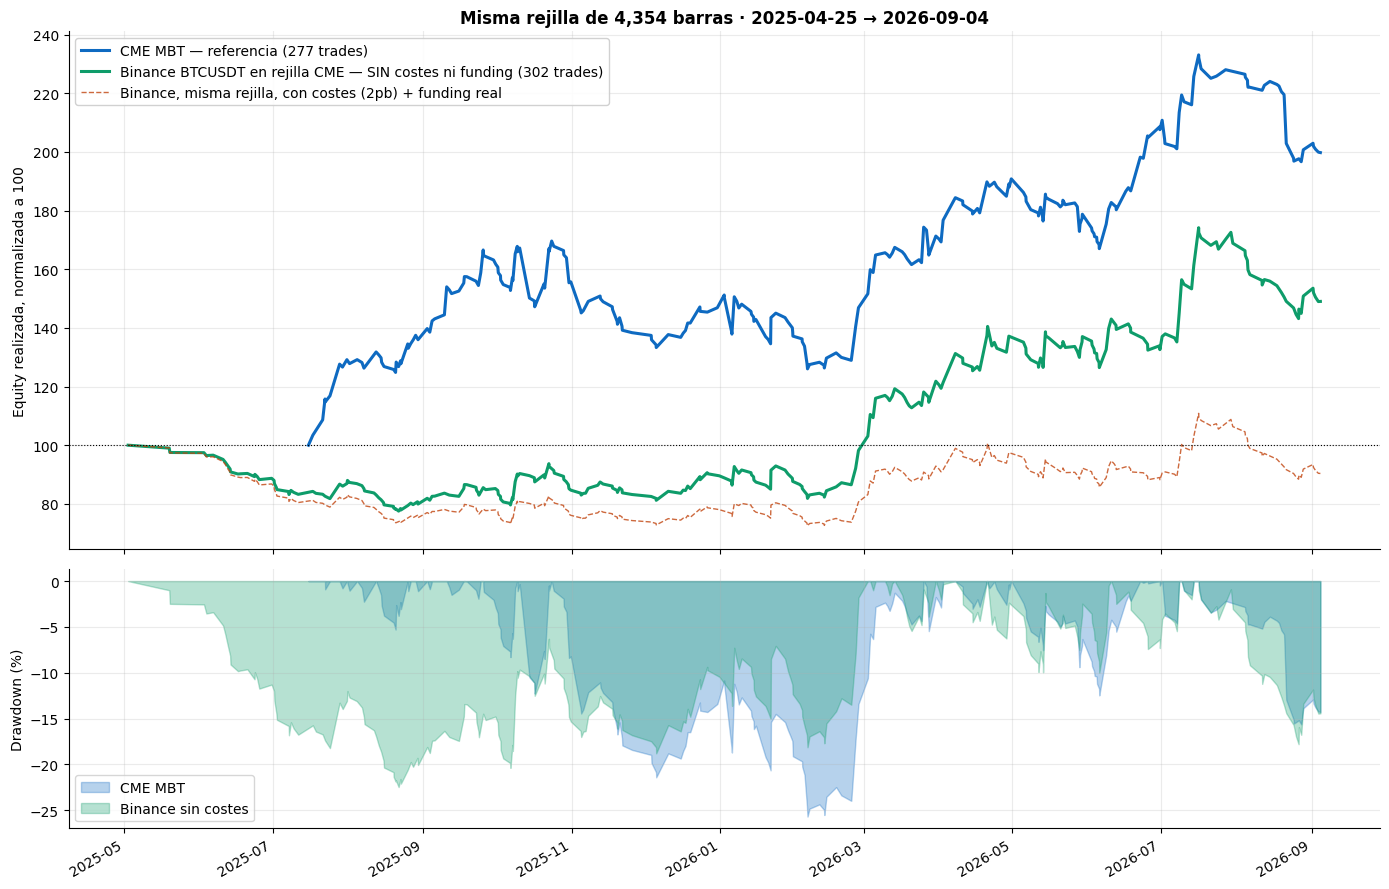

  CME MBT                equity final   199.8  (+99.8%)   MaxDD -25.7%   trades 277
  Binance sin costes     equity final   149.0  (+49.0%)   MaxDD -22.5%   trades 302
  Binance con costes     equity final    90.4  (-9.6%)   MaxDD -27.5%   trades 302


In [99]:
ec_bare, trades_bare = run_backtest(
    df_cmegrid, BacktestParams(equity0=100_000.0, fee_bps=0.0, slip_bps=0.0),
    funding=pd.Series(0.0, index=fund_match.index))

def curva_realizada(tr, eq0=100_000.0):
    if not len(tr):
        return pd.Series([eq0], index=[CME_START])
    s = tr.set_index("closed")["pnl"].sort_index().cumsum() + eq0
    return s / s.iloc[0] * 100

cur_cme   = curva_realizada(CME_TRADES)
cur_bare  = curva_realizada(trades_bare)
cur_costes = curva_realizada(trades_grid)

fig, ax = plt.subplots(2, 1, figsize=(14, 9), height_ratios=[2, 1], sharex=True)
ax[0].plot(cur_cme.index, cur_cme.values, color="#0e6ac1", lw=2.2,
          label=f"CME MBT — referencia ({len(CME_TRADES)} trades)")
ax[0].plot(cur_bare.index, cur_bare.values, color="#0e9c6a", lw=2.2,
          label=f"Binance BTCUSDT en rejilla CME — SIN costes ni funding ({len(trades_bare)} trades)")
ax[0].plot(cur_costes.index, cur_costes.values, color="#c1440e", lw=1.0, ls="--", alpha=0.8,
          label="Binance, misma rejilla, con costes (2pb) + funding real")
ax[0].axhline(100, color="k", ls=":", lw=0.8)
ax[0].set_ylabel("Equity realizada, normalizada a 100")
ax[0].set_title(f"Misma rejilla de {len(df_cmegrid):,} barras · {CME_START.date()} → {CME_END.date()}",
                fontweight="bold")
ax[0].legend(loc="upper left", framealpha=0.9)

for cur, lab, col in [(cur_cme, "CME MBT", "#0e6ac1"),
                      (cur_bare, "Binance sin costes", "#0e9c6a")]:
    ax[1].fill_between(cur.index, (cur/cur.cummax()-1)*100, 0, alpha=0.30, color=col, label=lab)
ax[1].set_ylabel("Drawdown (%)"); ax[1].legend(loc="lower left")
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

for lab, cur, tr in [("CME MBT", cur_cme, CME_TRADES),
                     ("Binance sin costes", cur_bare, trades_bare),
                     ("Binance con costes", cur_costes, trades_grid)]:
    dd = (cur/cur.cummax()-1).min()
    print(f"  {lab:22s} equity final {cur.iloc[-1]:7.1f}  ({cur.iloc[-1]-100:+.1f}%)   "
          f"MaxDD {dd:+.1%}   trades {len(tr)}")

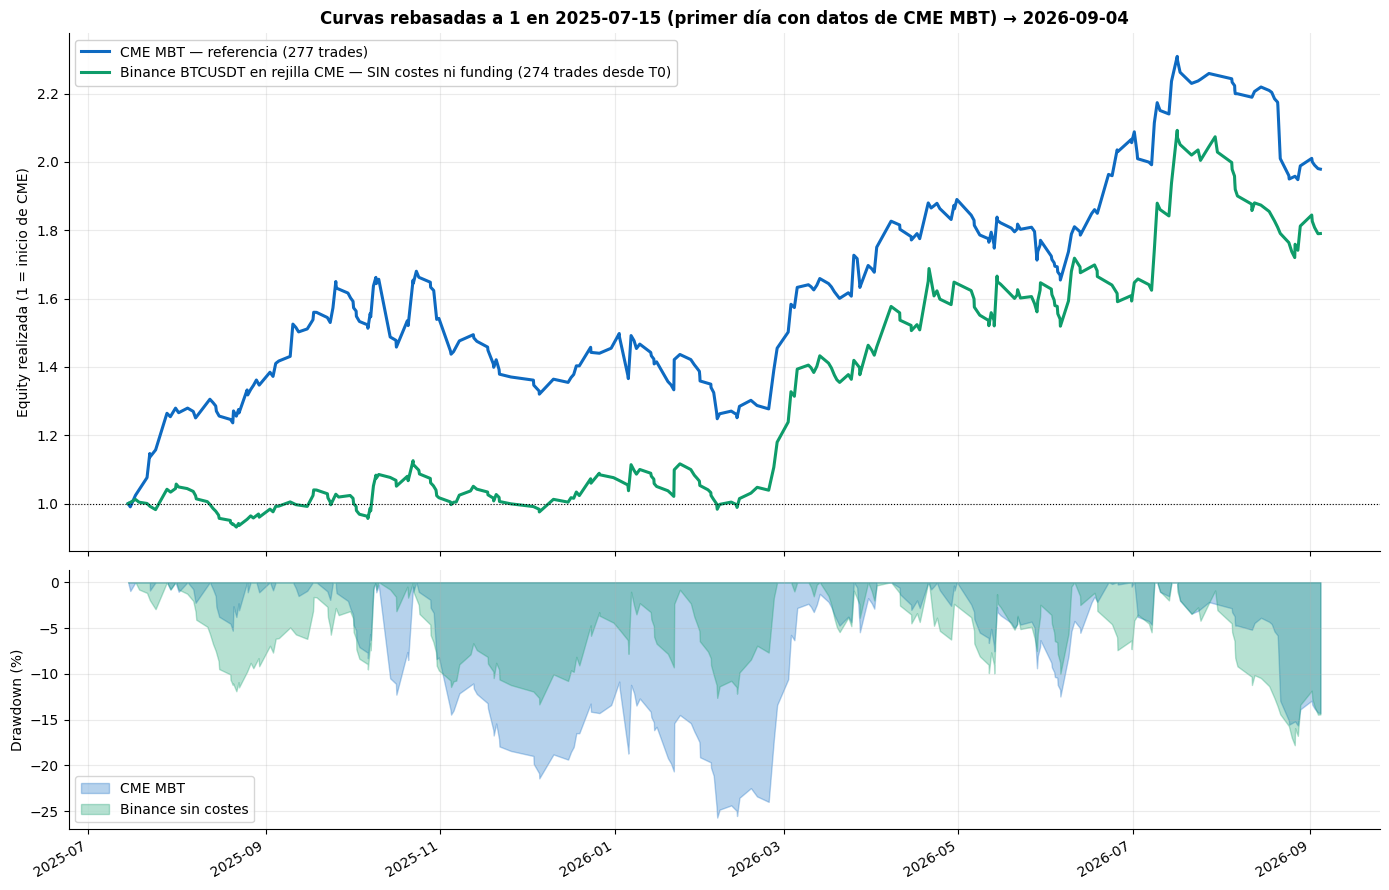

  CME MBT                desde 2025-07-15: x1.979  (+97.9%)   MaxDD -25.7%
  Binance sin costes     desde 2025-07-15: x1.790  (+79.0%)   MaxDD -17.8%


In [100]:
# Normaliza las dos curvas iniciando en 1 en el primer día que la curva CME MBT
# tiene datos (julio 2025). La ventana de barras arranca en CME_START, pero la
# primera operación de MBT no llega hasta 2025-07-15: antes de esa fecha la
# curva de CME no existe, así que la de Binance se rebasa al MISMO instante,
# usando la equity que tenía vigente ese día (P&L cerrado hasta entonces).
T0 = CME_TRADES["opened"].min().normalize()

def equity_realizada(tr, eq0=100_000.0):
    """Equity realizada en USD (acumulado de pnl al cierre), anclada a eq0 en CME_START."""
    ancla = pd.Series([eq0], index=[CME_START])
    if not len(tr):
        return ancla
    return pd.concat([ancla, tr.set_index("closed")["pnl"].sort_index().cumsum() + eq0])

def rebase_en(eq, t0=T0):
    """Curva que vale 1.0 en t0: equity vigente en t0 como base, solo puntos posteriores."""
    base = eq.asof(t0)
    return pd.concat([pd.Series([1.0], index=[t0]), eq.loc[eq.index > t0] / base])

eq1_cme  = rebase_en(equity_realizada(CME_TRADES))
eq1_bare = rebase_en(equity_realizada(trades_bare))

fig, ax = plt.subplots(2, 1, figsize=(14, 9), height_ratios=[2, 1], sharex=True)
ax[0].plot(eq1_cme.index, eq1_cme.values, color="#0e6ac1", lw=2.2,
           label=f"CME MBT — referencia ({len(CME_TRADES)} trades)")
ax[0].plot(eq1_bare.index, eq1_bare.values, color="#0e9c6a", lw=2.2,
           label=f"Binance BTCUSDT en rejilla CME — SIN costes ni funding "
                 f"({(trades_bare['opened'] >= T0).sum()} trades desde T0)")
ax[0].axhline(1.0, color="k", ls=":", lw=0.8)
ax[0].set_ylabel("Equity realizada (1 = inicio de CME)")
ax[0].set_title(f"Curvas rebasadas a 1 en {T0.date()} (primer día con datos de CME MBT) → "
                f"{CME_END.date()}", fontweight="bold")
ax[0].legend(loc="upper left", framealpha=0.9)

for cur, lab, col in [(eq1_cme, "CME MBT", "#0e6ac1"),
                      (eq1_bare, "Binance sin costes", "#0e9c6a")]:
    ax[1].fill_between(cur.index, (cur / cur.cummax() - 1) * 100, 0, alpha=0.30,
                       color=col, label=lab)
ax[1].set_ylabel("Drawdown (%)"); ax[1].legend(loc="lower left")
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

for lab, cur in [("CME MBT", eq1_cme), ("Binance sin costes", eq1_bare)]:
    print(f"  {lab:22s} desde {T0.date()}: x{cur.iloc[-1]:.3f}  ({cur.iloc[-1] - 1:+.1%})   "
          f"MaxDD {(cur / cur.cummax() - 1).min():+.1%}")


### 12.6 Conclusión de la comparación

Con la rejilla de barras igualada al timestamp, el diagnóstico cambia respecto de lo que sugería
la comparación 24/7:

1. **La hipótesis del horario era correcta y explica la mayor parte de la brecha.** Las barras
   fuera de sesión no solo añaden operaciones de calidad marginal: contaminan el cálculo de N y del
   canal para *todas* las señales. Igualando la rejilla, los trades caen de 1,841 a ~309 (CME: 277)
   y el signo del edge cambia.
2. **El edge desnudo de BTCUSDT sobre la rejilla de CME es POSITIVO** (ver §12.5). La señal
   funciona en el mismo activo y las mismas horas. Lo que la hundía antes era el **supuesto de
   coste**: los defaults anteriores (4 pb de comisión + 10 pb de slippage por lado) costaban
   **0.42 R por round-trip**, frente a los 0.03 R que paga MBT en CME. Ese slippage de 10 pb era
   un valor genérico pensado para todo el universo piloto —incluidos nombres finos como AVAX o
   LINK— y aplicado a BTCUSDT, el par más líquido del exchange, no es defendible. Los defaults
   actuales (2 pb de comisión + 1 pb de slippage) dejan el round-trip en ~0.09 R, del mismo orden
   que CME. **Sigue siendo un supuesto**: hay que medirlo contra el libro antes de darlo por bueno,
   y revisarlo al alza para los pares menos líquidos del piloto.
3. **El funding no es el problema** (~4%/año realizado en esta ventana; efecto aislado ~0.02 pp
   de CAGR). El instrumento cobra funding y CME no, pero en esta muestra es de segundo orden.
4. **Queda una ventaja estructural de CME que no es edge de la señal**: el 8.4% de velas planas de
   MBT son barras en las que el motor no puede ejecutar ningún stop, de modo que la posición
   sobrevive por construcción; en BTCUSDT ese porcentaje es 0%. Sumado al +14.77% de salto de
   empalme de contrato que el propio notebook de CME mide, una parte del +63.22% de la referencia
   no viene de la estrategia.

**Implicación práctica**: el orden de las decisiones importa más que los parámetros. Operar 24/7
con un canal y un N calibrados sobre una sesión de 7h es, según esta medición, lo que más daño
hace; el segundo factor es el supuesto de fricción, que hay que medir y no heredar de un default
pensado para otro activo.

## 13. Extensión a BTC/USDC, ETH/USDC y SOL/USDC — cuenta de market maker sin comisiones

**Premisa del escenario**: los perpetuos USDⓈ-M liquidados en USDC (`BTCUSDC`, `ETHUSDC`,
`SOLUSDC`) operan **sin comisión** para un market maker registrado, condición alcanzable con una
cuenta de **100k**. La pregunta operativa no es solo si la estrategia gana dinero ahí, sino **qué
volumen nocional total (en USDT) negocia cada mes** con un apalancamiento máximo de **10x**:
es la cifra contra la que se mide la elegibilidad y el mantenimiento del programa.

Qué cambia respecto de §6–§12:

| | §6–§12 | §13 |
|---|---|---|
| Instrumentos | `*USDT` | `BTCUSDC`, `ETHUSDC`, `SOLUSDC` (listados el 2024-01-03) |
| Comisión | 2 pb por lado | **0** (premisa MM); 2 pb como sensibilidad |
| Cuenta | un `run_backtest` por símbolo, equity repartida | **una sola cuenta de 100k** (`run_portfolio_backtest`) |
| Apalancamiento | 4x por símbolo, recortando cada unidad | **10x bruto de TODA la cuenta**, rechazando la orden que no cabe |
| Volumen | no se medía | cada fill (entrada, add, salida) con su nocional |

`run_portfolio_backtest` (`qsCrypto/backtest/engine.py`) replica los topes de
`BinancePerpetualsPortfolio` en vivo: apalancamiento bruto de la cuenta (`_fits_leverage`),
unidades por dirección (12) y por grupo de correlación y dirección (6) en las entradas, y
`max_units=3` para SOL (`risk_overrides` del universo). El riesgo del 1% por operación se mide
sobre la equity de **toda** la cuenta. La máquina de señal y las barreras son las mismas que
`run_backtest` (mismo código, refactorizado en un libro por símbolo); `run_backtest` reproduce
bit a bit los resultados anteriores y hay tests de paridad en `engine_test.py`.

In [ ]:
import requests
from qsCrypto.backtest.engine import run_portfolio_backtest
from qsCrypto.backtest.binance_data import fetch_klines_history, fetch_funding_history

# Mismo activo base que el piloto USDT: se heredan grupo de correlación y
# overrides de riesgo (max_units=3 en SOL) del universo, no se reescriben.
USDC_MAP = {"BTCUSDC": "BTCUSDT", "ETHUSDC": "ETHUSDT", "SOLUSDC": "SOLUSDT"}
USDC_SYMBOLS = list(USDC_MAP)
USDC_START = "2024-01-01"            # listados el 2024-01-03; el fetcher arranca en la 1ª vela
MM_EQUITY0 = 100_000.0
MM_MAX_LEV = 10.0
MM_CORR_GROUPS = {s: UNIVERSE.corr_groups[u] for s, u in USDC_MAP.items()}
MM_OVERRIDES = {s: UNIVERSE.risk_overrides.get(u, {}) for s, u in USDC_MAP.items()}

DATA_USDC, FUND_USDC = {}, {}
for s in USDC_SYMBOLS:
    DATA_USDC[s] = fetch_klines_history(s, interval=INTERVAL, start=USDC_START, end=END)
    FUND_USDC[s] = fetch_funding_history(s, start=USDC_START, end=END)

# Volumen del MERCADO por mes (nocional en USDC ≈ volumen base × cierre): el
# denominador para medir qué cuota del mercado representaría la cuenta.
MKT_VOL_M = pd.DataFrame({s: (d["volume"] * d["close"]).resample("ME").sum()
                          for s, d in DATA_USDC.items()})

display(pd.DataFrame([
    {"symbol": s, "inicio": d.index[0], "fin": d.index[-1], "barras": len(d),
     "funding": len(FUND_USDC[s]), "grupo_corr": MM_CORR_GROUPS[s],
     "overrides": MM_OVERRIDES[s] or "-",
     "velas planas": np.mean([is_flat_bar(h, l, v) for h, l, v in
                              zip(d["high"], d["low"], d["volume"])]),
     "vol. mercado/mes 1er mes (M)": MKT_VOL_M[s].iloc[0] / 1e6,
     "vol. mercado/mes mediana (M)": MKT_VOL_M[s].median() / 1e6}
    for s, d in DATA_USDC.items()]).style.format({
        "velas planas": "{:.2%}", "vol. mercado/mes 1er mes (M)": "{:,.0f}",
        "vol. mercado/mes mediana (M)": "{:,.0f}"}))

,symbol,inicio,fin,barras,funding,grupo_corr,overrides,velas planas,vol. mercado/mes 1er mes (M),vol. mercado/mes mediana (M)
0,BTCUSDC,2024-01-04 12:30:00,2026-09-09 17:30:00,47003,2944,layer1_major,-,0.00%,"4,655","65,712"
1,ETHUSDC,2024-01-04 12:30:00,2026-09-09 17:30:00,47003,2944,layer1_major,-,0.00%,"1,966","36,250"
2,SOLUSDC,2024-01-04 12:30:00,2026-09-09 17:30:00,47003,2944,layer1_alt,{'max_units': 3},0.00%,834,"8,026"


In [ ]:
def fetch_usdc_usdt_daily(start, end):
    """Cierre diario de USDC/USDT (spot, endpoint público). Los perpetuos USDC
    se liquidan en USDC; el volumen se pide en USDT, así que cada fill se
    convierte al tipo de su día en vez de suponer 1:1."""
    url = "https://api.binance.com/api/v3/klines"
    cur = int(pd.Timestamp(start, tz="UTC").timestamp() * 1000)
    end_ms = int(pd.Timestamp(end, tz="UTC").timestamp() * 1000)
    rows = []
    while cur < end_ms:
        batch = requests.get(url, params={"symbol": "USDCUSDT", "interval": "1d",
                                          "startTime": cur, "endTime": end_ms,
                                          "limit": 1000}, timeout=30).json()
        if not batch:
            break
        rows += batch
        cur = batch[-1][0] + 1
    return pd.Series([float(r[4]) for r in rows],
                     index=pd.to_datetime([r[0] for r in rows], unit="ms"),
                     name="USDCUSDT")

USDC_USDT = fetch_usdc_usdt_daily(USDC_START, END)
print(f"USDC/USDT diario: {len(USDC_USDT)} días, rango [{USDC_USDT.min():.4f}, "
      f"{USDC_USDT.max():.4f}], desviación media |1-x| = {(USDC_USDT - 1).abs().mean():.3%}")

def to_usdt(fills):
    rate = USDC_USDT.reindex(fills["time"].dt.normalize()).ffill().bfill().to_numpy()
    return fills.assign(notional_usdt=fills["notional"].to_numpy() * rate)

USDC/USDT diario: 983 días, rango [0.9977, 1.0021], desviación media |1-x| = 0.043%


### 13.1 Dos regímenes de sesión y una rejilla de costes

§12.4–12.6 midieron que el horario es el factor dominante: sobre 24/7 el fade pierde **incluso sin
costes**, y restringido a la rejilla de la sesión de CME el edge desnudo es positivo. Aquí se
corren los dos regímenes sobre los perpetuos USDC:

* **24/7** — todas las barras, como opera Binance.
* **Sesión CME** — solo barras de 13:30 a 20:15 UTC en días laborables, la ventana que usa el
  backtest de CME (`between_time("13:30", "20:15")`, igual que §12.4). N, canal y señales se
  calculan sobre esa rejilla; fuera de ella la cuenta no opera.

La comisión es 0 (premisa MM). El slippage **no** desaparece por ser market maker: se prueban 0,
1 y 3 pb por lado, y un escenario de control con 2 pb de comisión. Apalancamiento 10x y, como
referencia, el 4x del resto del notebook.

In [ ]:
def session_cme(d):
    d = d.between_time("13:30", "20:15", inclusive="left")
    return d[d.index.dayofweek < 5]

REGIMES = {"24/7": DATA_USDC,
           "Sesión CME": {s: session_cme(d) for s, d in DATA_USDC.items()}}
REGIME_BPY = {k: len(v["BTCUSDC"]) / ((v["BTCUSDC"].index[-1] - v["BTCUSDC"].index[0]).days / 365.25)
              for k, v in REGIMES.items()}

def run_mm(regime, lev=MM_MAX_LEV, fee=0.0, slip=0.0001):
    p = BacktestParams(equity0=MM_EQUITY0, max_gross_lev=lev, fee_bps=fee, slip_bps=slip)
    sp = {s: BacktestParams(**{**p.__dict__, **MM_OVERRIDES[s]}) for s in USDC_SYMBOLS}
    ec, tr, fills = run_portfolio_backtest(
        REGIMES[regime], p, funding=FUND_USDC, symbol_params=sp,
        corr_groups=MM_CORR_GROUPS, max_dir_units=12, max_corr_units=6)
    return ec, tr, to_usdt(fills)

def summarize(regime, lev, fee, slip):
    ec, tr, fills = run_mm(regime, lev, fee, slip)
    m = equity_metrics(ec, tr, freq=REGIME_BPY[regime])
    vol_m = fills.set_index("time")["notional_usdt"].resample("ME").sum()
    turn_m = (vol_m / ec.resample("ME").mean()).dropna()
    lev_used = ec.attrs["gross"] / ec
    return {"régimen": regime, "lev máx": lev, "comisión pb": fee * 1e4, "slip pb": slip * 1e4,
            "CAGR": m.get("CAGR", np.nan), "Sharpe": m.get("Sharpe", np.nan),
            "Max DD": m.get("Max DD", np.nan), "equity final": ec.iloc[-1], "trades": len(tr),
            "vol/mes p50 (M USDT)": vol_m.median() / 1e6,
            "vol/mes p10 (M USDT)": vol_m.quantile(0.10) / 1e6,
            "rotación/mes p50 (x equity)": turn_m.median(),
            "lev usado p95": lev_used.quantile(0.95),
            "rechazos lev": tr.attrs["rejected"]["apalancamiento"]}

SCENARIOS = [(r, lev, fee, slip)
             for r in REGIMES
             for lev in (MM_MAX_LEV, 4.0)
             for fee, slip in ((0.0, 0.0), (0.0, 0.0001), (0.0, 0.0003), (0.0002, 0.0001))]
MM_GRID = pd.DataFrame([summarize(*sc) for sc in SCENARIOS])
display(MM_GRID.style.format({
    "lev máx": "{:.0f}x", "comisión pb": "{:.0f}", "slip pb": "{:.0f}", "CAGR": "{:+.1%}",
    "Sharpe": "{:.2f}", "Max DD": "{:.0%}", "equity final": "{:,.0f}",
    "vol/mes p50 (M USDT)": "{:,.1f}", "vol/mes p10 (M USDT)": "{:,.1f}",
    "rotación/mes p50 (x equity)": "{:.0f}", "lev usado p95": "{:.1f}"}))

,régimen,lev máx,comisión pb,slip pb,CAGR,Sharpe,Max DD,equity final,trades,vol/mes p50 (M USDT),vol/mes p10 (M USDT),rotación/mes p50 (x equity),lev usado p95,rechazos lev
0,24/7,10x,0,0,-90.5%,-1.07,-100%,182,5681,8.2,0.0,500,3.0,6258
1,24/7,10x,0,1,-91.2%,-1.20,-100%,149,4819,7.5,0.0,426,2.4,6962
2,24/7,10x,0,3,-91.8%,-0.95,-100%,125,3570,9.5,1.3,687,3.0,8817
3,24/7,10x,2,1,-90.6%,-0.78,-100%,175,3235,8.6,0.1,707,2.8,9073
4,24/7,4x,0,0,-78.9%,-1.02,-99%,"1,545",6561,4.7,0.3,512,3.4,7835
5,24/7,4x,0,1,-82.7%,-1.21,-99%,914,5229,2.7,0.0,437,3.0,8016
6,24/7,4x,0,3,-86.6%,-1.51,-100%,456,3849,0.7,0.0,262,2.8,9222
7,24/7,4x,2,1,-86.9%,-1.42,-100%,434,3755,0.8,0.0,264,2.9,9630
8,Sesión CME,10x,0,0,+69.8%,0.86,-47%,"413,119",2095,38.5,22.8,221,5.6,55
9,Sesión CME,10x,0,1,+41.5%,0.51,-48%,"253,790",2092,31.0,18.5,219,5.5,54


**Cómo leer la rejilla.** El volumen mensual es consecuencia de la equity: el sizing arriesga el 1%
de la cuenta por operación, así que una cuenta que se hunde negocia cada vez menos, y una que
crece, cada vez más. Por eso la columna estable es la **rotación** (volumen del mes ÷ equity media
del mes): es la intensidad de negociación del sistema, independiente de si gana o pierde, y
`rotación × 100k` es el volumen de una cuenta que se mantuviera en 100k.

In [ ]:
# Escenario central: sesión CME, 10x, sin comisión, 1 pb de slippage por lado.
MM_MAIN = ("Sesión CME", MM_MAX_LEV, 0.0, 0.0001)
EC_MM, TR_MM, FILLS_MM = run_mm(*MM_MAIN)

vol_sym = (FILLS_MM.set_index("time").groupby("symbol")["notional_usdt"]
           .resample("ME").sum().unstack(0).reindex(columns=USDC_SYMBOLS).fillna(0.0))
eq_m = EC_MM.resample("ME").mean()
VOL_MONTHLY = vol_sym.assign(
    total=vol_sym.sum(axis=1),
    equity_media=eq_m,
    rotación=lambda x: x["total"] / x["equity_media"],
    **{"a 100k constantes": lambda x: x["rotación"] * MM_EQUITY0},
    **{"cuota del mercado": lambda x: x["total"] / MKT_VOL_M.sum(axis=1)},
)
VOL_MONTHLY.index = VOL_MONTHLY.index.strftime("%Y-%m")
VOL_MONTHLY.to_csv(OUT / "usdc_mm_volumen_mensual.csv")

fmt_m = {c: (lambda v: f"{v/1e6:,.1f}M") for c in USDC_SYMBOLS + ["total", "a 100k constantes"]}
fmt_m.update({"equity_media": "{:,.0f}", "rotación": "{:.0f}x", "cuota del mercado": "{:.3%}"})
display(VOL_MONTHLY.style.format(fmt_m))

tot = VOL_MONTHLY["total"]
print(f"Volumen mensual total (USDT): mediana {tot.median()/1e6:,.1f}M | p10 {tot.quantile(.1)/1e6:,.1f}M"
      f" | p90 {tot.quantile(.9)/1e6:,.1f}M | mínimo {tot.min()/1e6:,.1f}M ({tot.idxmin()})")
print(f"A 100k constantes          : mediana {VOL_MONTHLY['a 100k constantes'].median()/1e6:,.1f}M"
      f" | p10 {VOL_MONTHLY['a 100k constantes'].quantile(.1)/1e6:,.1f}M")
print(f"(el primer y el último mes están incompletos: la muestra empieza el "
      f"{EC_MM.index[0].date()} y termina el {EC_MM.index[-1].date()})")

symbol,BTCUSDC,ETHUSDC,SOLUSDC,total,equity_media,rotación,a 100k constantes,cuota del mercado
time,,,,,,,,
2024-01,6.1M,8.0M,4.0M,18.1M,"101,849",177x,17.7M,0.242%
2024-02,4.9M,4.8M,2.8M,12.5M,"81,823",153x,15.3M,0.071%
2024-03,2.8M,3.1M,1.5M,7.4M,"78,727",94x,9.4M,0.016%
2024-04,9.2M,10.0M,2.8M,22.0M,"100,436",219x,21.9M,0.039%
2024-05,11.6M,10.9M,6.2M,28.7M,"106,986",268x,26.8M,0.034%
2024-06,11.6M,9.6M,9.7M,31.0M,"141,112",219x,21.9M,0.042%
2024-07,17.6M,11.2M,6.4M,35.2M,"143,844",245x,24.5M,0.056%
2024-08,7.3M,9.8M,7.2M,24.3M,"138,310",176x,17.6M,0.049%
2024-09,14.0M,8.6M,8.2M,30.9M,"129,935",238x,23.8M,0.116%


Volumen mensual total (USDT): mediana 31.0M | p10 18.5M | p90 63.7M | mínimo 7.4M (2024-03)
A 100k constantes          : mediana 21.9M | p10 15.3M
(el primer y el último mes están incompletos: la muestra empieza el 2024-01-04 y termina el 2026-09-09)


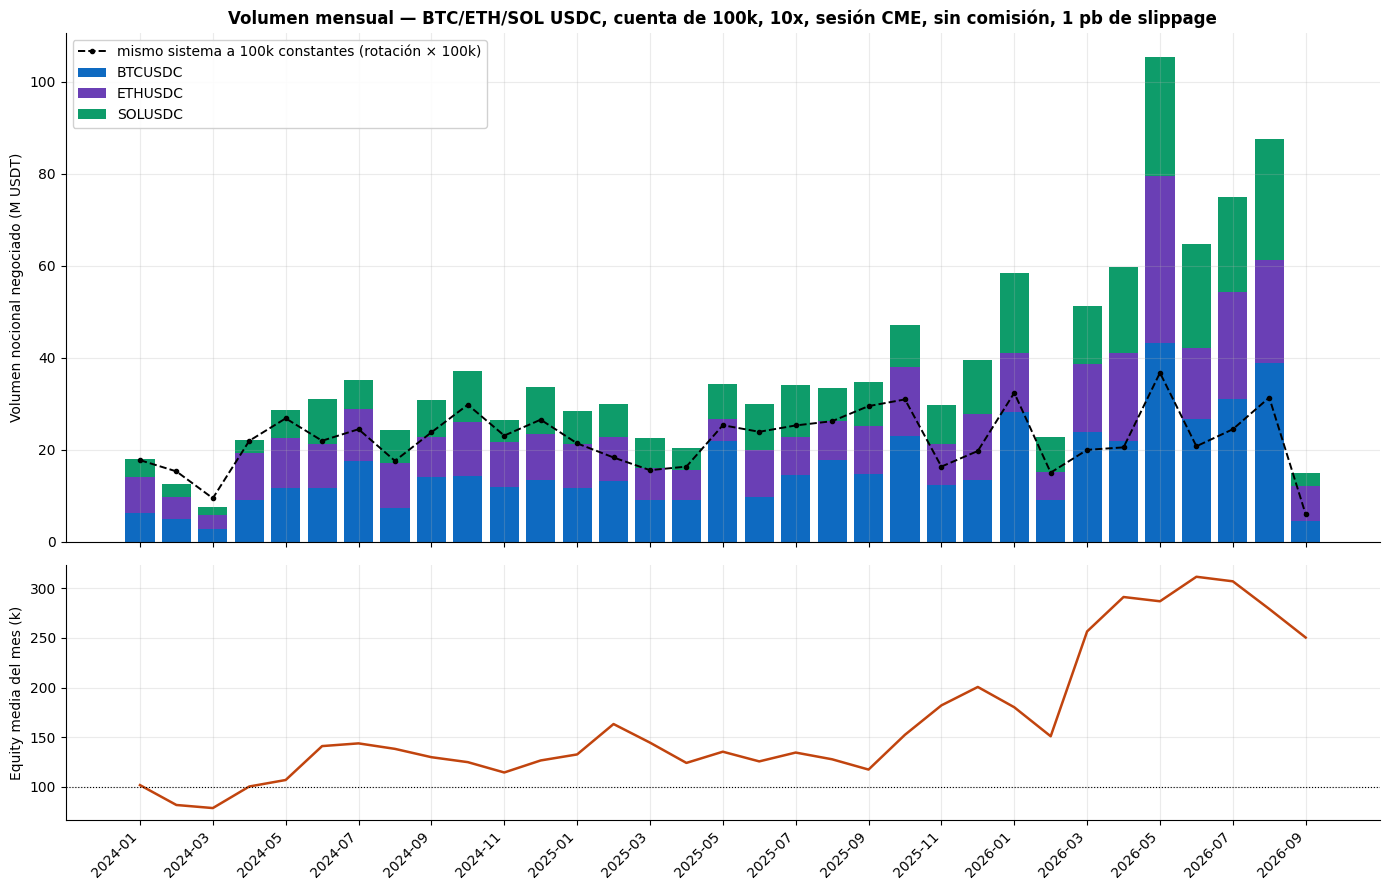

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(14, 9), height_ratios=[2, 1], sharex=True)
x = np.arange(len(VOL_MONTHLY))
bottom = np.zeros(len(VOL_MONTHLY))
for s, col in zip(USDC_SYMBOLS, ["#0e6ac1", "#6a3fb5", "#0e9c6a"]):
    ax[0].bar(x, VOL_MONTHLY[s] / 1e6, bottom=bottom, color=col, label=s, width=0.8)
    bottom += VOL_MONTHLY[s].to_numpy() / 1e6
ax[0].plot(x, VOL_MONTHLY["a 100k constantes"] / 1e6, color="k", lw=1.4, ls="--",
           marker="o", ms=3, label="mismo sistema a 100k constantes (rotación × 100k)")
ax[0].set_ylabel("Volumen nocional negociado (M USDT)")
ax[0].set_title("Volumen mensual — BTC/ETH/SOL USDC, cuenta de 100k, 10x, sesión CME, "
                "sin comisión, 1 pb de slippage", fontweight="bold")
ax[0].legend(loc="upper left", framealpha=0.9)

ax[1].plot(x, VOL_MONTHLY["equity_media"] / 1e3, color="#c1440e", lw=1.8)
ax[1].axhline(MM_EQUITY0 / 1e3, color="k", ls=":", lw=0.8)
ax[1].set_ylabel("Equity media del mes (k)")
ax[1].set_xticks(x[::2]); ax[1].set_xticklabels(VOL_MONTHLY.index[::2], rotation=45, ha="right")
plt.tight_layout(); plt.show()

### 13.2 ¿Qué parte de ese volumen puede ser maker?

La premisa "sin comisión" merece una comprobación explícita: los programas de market maker
remuneran sobre todo el flujo **maker** (órdenes límite que dan liquidez), y esta estrategia
consume liquidez casi siempre. Solo la salida al objetivo (el medio del canal, un precio conocido
de antemano) puede dejarse como orden límite; la entrada es a mercado al open, los adds se
disparan en un nivel que el precio atraviesa, el stop es stop-market y la barrera vertical cierra
a mercado.

In [ ]:
kind = np.where(FILLS_MM["kind"] == "exit", "salida: " + FILLS_MM["reason"].astype(str),
                FILLS_MM["kind"].map({"entry": "entrada", "add": "add (pirámide)"}))
COMP = (FILLS_MM.assign(tipo=kind).groupby("tipo")["notional_usdt"].sum()
        .to_frame("volumen").assign(cuota=lambda d: d["volumen"] / d["volumen"].sum()))
COMP["ejecución"] = ["límite (maker)" if t == "salida: target" else "a mercado (taker)"
                     for t in COMP.index]
display(COMP.sort_values("volumen", ascending=False).style.format(
    {"volumen": lambda v: f"{v/1e6:,.0f}M", "cuota": "{:.1%}"}))

maker_share = COMP.loc[COMP["ejecución"] == "límite (maker)", "cuota"].sum()
TAKER_BPS_HYP = BASELINE.fee_bps          # hipótesis: 2 pb si el taker NO fuera gratis
taker_vol_m = tot * (1 - maker_share)
pnl_m = TR_MM.set_index("closed")["pnl"].resample("ME").sum()
print(f"Volumen elegible como maker: {maker_share:.1%}   ·   a mercado (taker): {1 - maker_share:.1%}")
print(f"Si el taker pagara {TAKER_BPS_HYP*1e4:.0f} pb: ~{(taker_vol_m * TAKER_BPS_HYP).median():,.0f} USDT/mes "
      f"de comisión (mediana) frente a un P&L mensual mediano de {pnl_m.median():,.0f} USDT.")

,volumen,cuota,ejecución
tipo,,,
salida: stop,366M,29.8%,a mercado (taker)
entrada,366M,29.8%,a mercado (taker)
add (pirámide),249M,20.2%,a mercado (taker)
salida: target,176M,14.3%,límite (maker)
salida: vertical,72M,5.9%,a mercado (taker)


Volumen elegible como maker: 14.3%   ·   a mercado (taker): 85.7%
Si el taker pagara 2 pb: ~5,305 USDT/mes de comisión (mediana) frente a un P&L mensual mediano de 3,797 USDT.


### 13.3 ¿Es la sesión CME una elección hecha mirando el resultado?

Sí, en parte: la restricción a la sesión de CME salió de §12, que la probó sobre BTCUSDT entre
2025-04-25 y 2026-09-04 **después** de ver que 24/7 perdía. Esa ventana se solapa con la muestra
USDC, así que el resultado de §13.1 no es una validación independiente de la decisión. La parte de
la muestra USDC **anterior** a 2025-04-25 no intervino en ella y funciona como fuera de muestra
para esa elección concreta (no para los parámetros, que son los canónicos y no se tocaron).

In [ ]:
CUT = pd.Timestamp("2025-04-25")
rows = []
for lab, a, b in [("fuera de muestra (antes de §12)", EC_MM.index[0], CUT),
                  ("dentro de la ventana de §12", CUT, EC_MM.index[-1])]:
    e = EC_MM[(EC_MM.index >= a) & (EC_MM.index < b)]
    t = TR_MM[(TR_MM["opened"] >= a) & (TR_MM["opened"] < b)]
    m = equity_metrics(e, t, freq=REGIME_BPY["Sesión CME"])
    v = FILLS_MM[(FILLS_MM["time"] >= a) & (FILLS_MM["time"] < b)]
    v_m = v.set_index("time")["notional_usdt"].resample("ME").sum()
    rows.append({"tramo": lab, "desde": a.date(), "hasta": b.date(),
                 "retorno": e.iloc[-1] / e.iloc[0] - 1, "CAGR": m.get("CAGR", np.nan),
                 "Sharpe": m.get("Sharpe", np.nan), "Max DD": m.get("Max DD", np.nan),
                 "trades": len(t), "R media": t["r_multiple"].mean(),
                 "rotación/mes p50": (v_m / e.resample("ME").mean()).median()})
display(pd.DataFrame(rows).style.format({
    "retorno": "{:+.1%}", "CAGR": "{:+.1%}", "Sharpe": "{:.2f}", "Max DD": "{:.0%}",
    "R media": "{:+.3f}", "rotación/mes p50": "{:.0f}x"}))

,tramo,desde,hasta,retorno,CAGR,Sharpe,Max DD,trades,R media,rotación/mes p50
0,fuera de muestra (antes de §12),2024-01-04,2025-04-25,+23.2%,+17.4%,0.22,-42%,1053,+0.066,217x
1,dentro de la ventana de §12,2025-04-25,2026-09-09,+106.0%,+69.2%,0.86,-48%,1039,+0.107,242x


### 13.4 Conclusión — volumen, y lo que tiene que ser cierto para que ese volumen exista

**El volumen.** En el escenario central (sesión CME, 10x, sin comisión, 1 pb de slippage por
lado) la cuenta de 100k negocia una **mediana de ~31M USDT al mes** (p10 ~18.5M, p90 ~64M; el mes
más flojo, marzo 2024, 7.4M). La cifra crece con la equity, porque el sizing es un % de la cuenta;
el mismo sistema **manteniendo 100k** negociaría una mediana de **~22M USDT/mes** (p10 ~15M), es
decir, una rotación de ~220x la equity al mes. Frente al volumen de mercado de estos tres
contratos es una cuota del orden del **0.04%** (mediana). La conversión USDC→USDT se hace al tipo
diario real y apenas mueve nada (desviación media 0.04%).

**Lo que tiene que ser cierto — cinco condiciones, en orden de gravedad:**

1. **Operar solo en la sesión de CME.** En 24/7 la cuenta se liquida (CAGR ≈ −90%) **con cualquier
   coste, incluido cero**: el edge es negativo antes de fricción, lo mismo que midió §12. Sin
   comisión no se arregla un edge que no existe, y el volumen se desploma con la equity (p10 ≈ 0).
2. **Que "sin comisión" cubra también el flujo taker.** Solo el **14%** del volumen puede ser
   maker (salidas al objetivo); el **86%** es a mercado: entradas, adds, stops y verticales. Si
   la exención solo alcanza al maker, o si el programa exige un porcentaje mínimo de volumen maker,
   la premisa no se cumple. Con 2 pb de taker, la comisión (~5.3k USDT/mes de mediana) **supera** el
   P&L mensual mediano (~3.8k), y la rejilla con 2 pb da −18% de CAGR. **Hay que confirmar las
   condiciones exactas del programa antes de contar con este volumen.**
3. **Slippage ≤ ~1 pb por lado en los libros USDC.** Con 3 pb el escenario central pasa de +41% a
   −15% de CAGR. Los libros USDC son más finos que los USDT (SOLUSDC mueve ~8B/mes frente a ~66B
   de BTCUSDC), así que este supuesto se tiene que **medir** contra el libro antes de darlo por
   bueno, igual que advertía §12 para los USDT.
4. **El +41% es optimista.** La elección de la sesión salió de §12, que la probó sobre una ventana
   que se solapa con esta muestra. En el tramo que no intervino en esa decisión (2024-01 →
   2025-04), el sistema sin comisión y con 1 pb gana **+17% de CAGR con Sharpe 0.22** (R media
   +0.066), frente a +69% y 0.86 en la ventana de §12. El edge sigue siendo positivo fuera de
   muestra, pero mucho más pequeño.
5. **Aceptar drawdowns del ~48%.** A 10x el apalancamiento que de verdad se usa es moderado (p95
   5.5x, 54 rechazos en toda la muestra): el tope casi nunca actúa. Frente a 4x, 10x añade
   **volumen** (~31M frente a ~24M/mes) más que rentabilidad (CAGR parecido, Sharpe 0.51 frente a
   0.66). Si el objetivo es solo el volumen del programa, esa es la palanca; si es el retorno
   ajustado por riesgo, no lo es.

**Implicación práctica**: la cuenta de 100k llegaría a ~20–30M USDT/mes en BTC/ETH/SOL-USDC
**solo** operando en la sesión de CME. El siguiente paso no es optimizar parámetros, sino cerrar las
dos incógnitas externas que deciden el signo: (a) las condiciones exactas del programa MM sobre el
flujo taker y (b) el slippage real de los libros USDC en esas horas.